# ✈️ 2015 US Flight Delays and Cancellations: Complete Data Analysis
### pandas · NumPy · Matplotlib · Seaborn · SciPy · statsmodels · Plotly · scikit-learn · missingno

**Dataset:** [2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays) from the U.S. Department of Transportation on Kaggle.
Three files: `flights.csv` (5,819,079 flights, 31 columns), `airlines.csv` (14 carriers) and `airports.csv` (322 airports).
Analysis sample: **4,000,000 flights** (`N_ROWS`).

| # | Section |
|---|---------|
| 1 | Setup |
| 2 | Loading & merging |
| 3 | First look |
| 4 | Memory optimisation |
| 5 | Missing values |
| 6 | Cleaning & outliers |
| 7 | Feature engineering |
| 8 | NumPy |
| 9 | Advanced pandas |
| 10 | Univariate analysis |
| 11 | Time analysis |
| 12 | Bivariate & multivariate analysis |
| 13 | Geospatial analysis |
| 14 | Route network analysis |
| 15 | Statistical tests (SciPy) |
| 16 | Statistical modelling & time series (statsmodels) |
| 17 | Interactive dashboards (Plotly) |
| 18 | Unsupervised learning |
| 19 | Predicting delays (scikit-learn) |
| 20 | Export & key findings |

In [1]:
import os, re, gc, glob, time, math, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import missingno as msno

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import plotly.express as px
import plotly.graph_objects as go

from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
                             PrecisionRecallDisplay, average_precision_score, f1_score, silhouette_score,
                             mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 42
N_ROWS = 4_000_000
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 5), "figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def samp(frame, n):
    return frame.sample(min(n, len(frame)), random_state=SEED)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight", dpi=110)

for lib in (np, pd, sns, plt.matplotlib, stats, sm):
    print(f"{getattr(lib, '__name__', ''):<22} {getattr(lib, '__version__', '')}")

numpy                  2.1.3
pandas                 2.3.3
seaborn                0.13.2
matplotlib             3.10.0
scipy.stats            
statsmodels.api        0.15.0


## 2. Loading & merging

In [2]:
def find_dir():
    env = os.environ.get("FLIGHTS_DIR")
    if env and os.path.exists(os.path.join(env, "flights.csv")):
        return env
    hits = glob.glob("/kaggle/input/**/flights.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    import kagglehub
    folder = kagglehub.dataset_download("usdot/flight-delays")
    return os.path.dirname(glob.glob(os.path.join(folder, "**", "flights.csv"), recursive=True)[0])

DATA_DIR = find_dir()
code_types = {"ORIGIN_AIRPORT": str, "DESTINATION_AIRPORT": str, "TAIL_NUMBER": str, "CANCELLATION_REASON": str}
flights_path = os.path.join(DATA_DIR, "flights.csv")
print("Reading:", flights_path, f"({os.path.getsize(flights_path)/1e6:,.0f} MB)")

t0 = time.time()
try:
    flights = pd.read_csv(flights_path, engine="pyarrow", dtype=code_types)
except Exception as e:
    print("pyarrow engine unavailable:", type(e).__name__)
    flights = pd.read_csv(flights_path, dtype=code_types, low_memory=False)
airlines = pd.read_csv(os.path.join(DATA_DIR, "airlines.csv"))
airports = pd.read_csv(os.path.join(DATA_DIR, "airports.csv"))
print(f"flights {flights.shape} | airlines {airlines.shape} | airports {airports.shape} | {time.time()-t0:.1f}s")

Reading: /kaggle/input/datasets/usdot/flight-delays/flights.csv (592 MB)
flights (5819079, 31) | airlines (14, 2) | airports (322, 7) | 13.7s


In [3]:
numeric_code = (flights["ORIGIN_AIRPORT"].str.fullmatch(r"\d+").fillna(False) |
                flights["DESTINATION_AIRPORT"].str.fullmatch(r"\d+").fillna(False))
print(f"Rows with numeric airport codes (October 2015 quirk), removed: {numeric_code.sum():,}")
flights = flights.loc[~numeric_code]

if N_ROWS and len(flights) > N_ROWS:
    df = flights.sample(n=N_ROWS, random_state=SEED).reset_index(drop=True)
else:
    df = flights.reset_index(drop=True)
del flights; gc.collect()
print(f"Working sample: {len(df):,} flights")

Rows with numeric airport codes (October 2015 quirk), removed: 486,165
Working sample: 4,000,000 flights


In [4]:
airlines = airlines.rename(columns={"IATA_CODE": "AIRLINE", "AIRLINE": "AIRLINE_NAME"})
ap = airports.rename(columns=str.upper)
orig = ap.add_prefix("ORIG_").rename(columns={"ORIG_IATA_CODE": "ORIGIN_AIRPORT"})
dest = ap.add_prefix("DEST_").rename(columns={"DEST_IATA_CODE": "DESTINATION_AIRPORT"})

df = (df.merge(airlines, on="AIRLINE", how="left", validate="m:1")
        .merge(orig, on="ORIGIN_AIRPORT", how="left", validate="m:1")
        .merge(dest, on="DESTINATION_AIRPORT", how="left", validate="m:1"))
print(df.shape)
print("Unmatched airlines:", df["AIRLINE_NAME"].isna().sum(), "| unmatched origins:", df["ORIG_AIRPORT"].isna().sum())

(4000000, 44)
Unmatched airlines: 0 | unmatched origins: 0


## 3. First look

In [5]:
print(df.shape)
df.head()

(4000000, 44)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_NAME,ORIG_AIRPORT,ORIG_CITY,ORIG_STATE,ORIG_COUNTRY,ORIG_LATITUDE,ORIG_LONGITUDE,DEST_AIRPORT,DEST_CITY,DEST_STATE,DEST_COUNTRY,DEST_LATITUDE,DEST_LONGITUDE
0,2015,9,18,5,B6,23,N923JB,JFK,LAX,700,655.000,-5.000,27.000,722.000,359.000,356.000,324.000,2475,946.000,5.000,959,951.000,-8.000,0,0,None,NaN,NaN,NaN,NaN,NaN,JetBlue Airways,John F. Kennedy International Airport (New Yor...,New York,NY,USA,40.640,-73.779,Los Angeles International Airport,Los Angeles,CA,USA,33.943,-118.408
1,2015,4,8,3,US,1745,N838AW,IAH,CLT,1205,"1,221.000",16.000,10.000,"1,231.000",145.000,139.000,122.000,912,"1,533.000",7.000,1530,"1,540.000",10.000,0,0,None,NaN,NaN,NaN,NaN,NaN,US Airways Inc.,George Bush Intercontinental Airport,Houston,TX,USA,29.980,-95.340,Charlotte Douglas International Airport,Charlotte,NC,USA,35.214,-80.943
2,2015,7,23,4,MQ,3384,N642MQ,MLI,ORD,555,604.000,9.000,10.000,614.000,61.000,44.000,30.000,139,644.000,4.000,656,648.000,-8.000,0,0,None,NaN,NaN,NaN,NaN,NaN,American Eagle Airlines Inc.,Quad City International Airport,Moline,IL,USA,41.449,-90.508,Chicago O'Hare International Airport,Chicago,IL,USA,41.980,-87.904
3,2015,9,14,1,WN,1913,N478WN,LAS,IAD,1530,"1,536.000",6.000,12.000,"1,548.000",275.000,257.000,240.000,2065,"2,248.000",5.000,2305,"2,253.000",-12.000,0,0,None,NaN,NaN,NaN,NaN,NaN,Southwest Airlines Co.,McCarran International Airport,Las Vegas,NV,USA,36.080,-115.152,Washington Dulles International Airport,Chantilly,VA,USA,38.945,-77.456
4,2015,7,9,4,EV,5165,N582CA,ATL,GRK,1030,"1,027.000",-3.000,13.000,"1,040.000",134.000,118.000,103.000,803,"1,123.000",2.000,1144,"1,125.000",-19.000,0,0,None,NaN,NaN,NaN,NaN,NaN,Atlantic Southeast Airlines,Hartsfield-Jackson Atlanta International Airport,Atlanta,GA,USA,33.640,-84.427,Killeen-Fort Hood Regional Airport,Killeen,TX,USA,31.065,-97.828


In [6]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000000 entries, 0 to 3999999
Data columns (total 44 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24

In [7]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_%": df.isna().mean().mul(100).round(2),
    "n_unique": df.nunique(dropna=True),
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
})
overview

,dtype,missing_%,n_unique,example
YEAR,int64,0.000,1,2015
MONTH,int64,0.000,11,9
DAY,int64,0.000,31,18
DAY_OF_WEEK,int64,0.000,7,5
AIRLINE,object,0.000,14,B6
FLIGHT_NUMBER,int64,0.000,6938,23
TAIL_NUMBER,object,0.000,4892,N923JB
ORIGIN_AIRPORT,object,0.000,322,JFK
DESTINATION_AIRPORT,object,0.000,322,LAX
SCHEDULED_DEPARTURE,int64,0.000,1310,700


In [8]:
df.describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
YEAR,"4,000,000.000","2,015.000",0.000,"2,015.000","2,015.000","2,015.000","2,015.000","2,015.000","2,015.000","2,015.000"
MONTH,"4,000,000.000",6.206,3.383,1.000,1.000,3.000,6.000,9.000,12.000,12.000
DAY,"4,000,000.000",15.693,8.774,1.000,1.000,8.000,16.000,23.000,31.000,31.000
DAY_OF_WEEK,"4,000,000.000",3.919,1.993,1.000,1.000,2.000,4.000,6.000,7.000,7.000
FLIGHT_NUMBER,"4,000,000.000","2,177.935","1,760.128",1.000,29.000,731.000,"1,690.000","3,251.000","6,459.000","9,794.000"
SCHEDULED_DEPARTURE,"4,000,000.000","1,330.069",484.193,1.000,529.000,917.000,"1,325.000","1,730.000","2,245.000","2,359.000"
DEPARTURE_TIME,"3,936,967.000","1,336.060",497.285,1.000,510.000,921.000,"1,331.000","1,740.000","2,300.000","2,400.000"
DEPARTURE_DELAY,"3,936,967.000",9.778,37.588,-82.000,-13.000,-5.000,-1.000,8.000,170.000,"1,988.000"
TAXI_OUT,"3,934,847.000",16.103,8.992,1.000,6.000,11.000,14.000,19.000,51.000,225.000
WHEELS_OFF,"3,934,847.000","1,357.870",498.940,1.000,508.000,935.000,"1,344.000","1,755.000","2,308.000","2,400.000"


In [9]:
df.describe(include=["object", "string"]).T

,count,unique,top,freq
AIRLINE,4000000,14,WN,867855
TAIL_NUMBER,4000000,4892,None,10802
ORIGIN_AIRPORT,4000000,322,ATL,259983
DESTINATION_AIRPORT,4000000,322,ATL,259851
CANCELLATION_REASON,4000000,5,None,3934220
AIRLINE_NAME,4000000,14,Southwest Airlines Co.,867855
ORIG_AIRPORT,4000000,322,Hartsfield-Jackson Atlanta International Airport,259983
ORIG_CITY,4000000,308,Chicago,274933
ORIG_STATE,4000000,54,CA,486134
ORIG_COUNTRY,4000000,1,USA,4000000


## 4. Memory optimisation

In [10]:
def mem_mb(frame):
    return frame.memory_usage(deep=True).sum() / 1024**2

before = mem_mb(df)
float_cols = df.select_dtypes(include="float").columns
int_cols = df.select_dtypes(include="integer").columns
df[float_cols] = df[float_cols].apply(pd.to_numeric, downcast="float")
df[int_cols] = df[int_cols].apply(pd.to_numeric, downcast="integer")

CAT_COLS = ["AIRLINE", "AIRLINE_NAME", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "TAIL_NUMBER", "CANCELLATION_REASON",
            "ORIG_AIRPORT", "ORIG_CITY", "ORIG_STATE", "ORIG_COUNTRY", "DEST_AIRPORT", "DEST_CITY", "DEST_STATE", "DEST_COUNTRY"]
for c in CAT_COLS:
    if c in df:
        df[c] = df[c].astype("category")

after = mem_mb(df)
print(f"Memory: {before:,.0f} MB → {after:,.0f} MB ({1-after/before:.0%} saved)")

Memory: 4,110 MB → 443 MB (89% saved)


## 5. Missing values

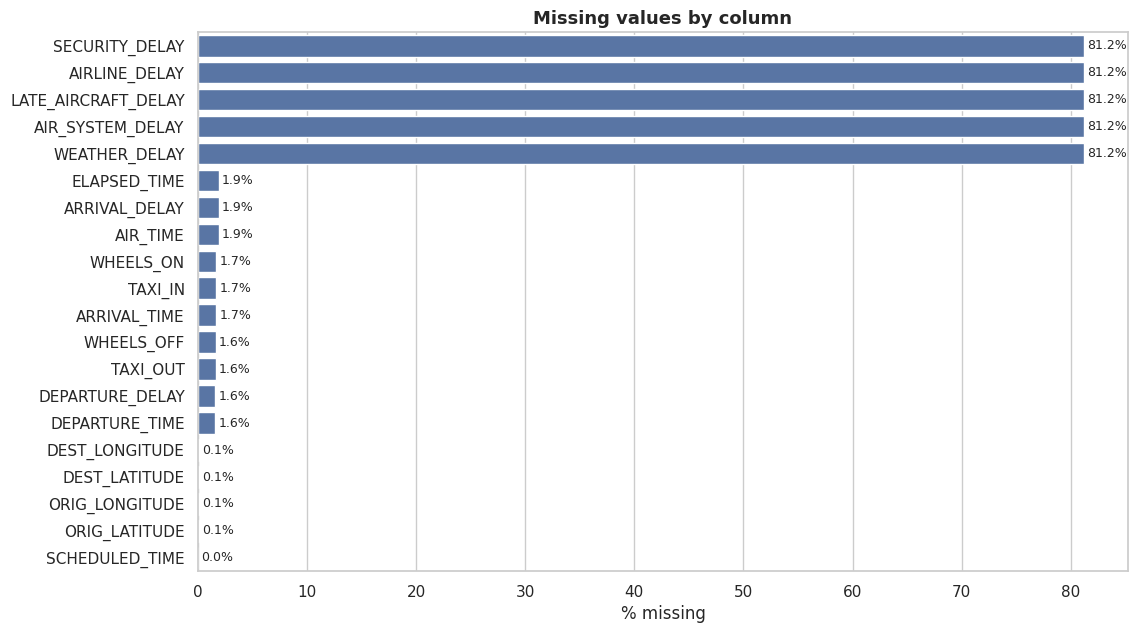

,n_missing,pct
SECURITY_DELAY,3247394,81.185
AIRLINE_DELAY,3247394,81.185
LATE_AIRCRAFT_DELAY,3247394,81.185
AIR_SYSTEM_DELAY,3247394,81.185
WEATHER_DELAY,3247394,81.185
ELAPSED_TIME,76523,1.913
ARRIVAL_DELAY,76523,1.913
AIR_TIME,76523,1.913
WHEELS_ON,67668,1.692
TAXI_IN,67668,1.692


In [11]:
missing = (df.isna().sum().to_frame("n_missing")
             .assign(pct=lambda d: d.n_missing / len(df) * 100)
             .query("n_missing > 0").sort_values("pct", ascending=False))

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=missing.reset_index(), y="index", x="pct", ax=ax, color="#4C72B0")
ax.set(title="Missing values by column", xlabel="% missing", ylabel="")
for p in ax.patches:
    ax.text(p.get_width() + .3, p.get_y() + p.get_height() / 2, f"{p.get_width():.1f}%", va="center", fontsize=9)
savefig("missing_bar"); plt.show()
missing

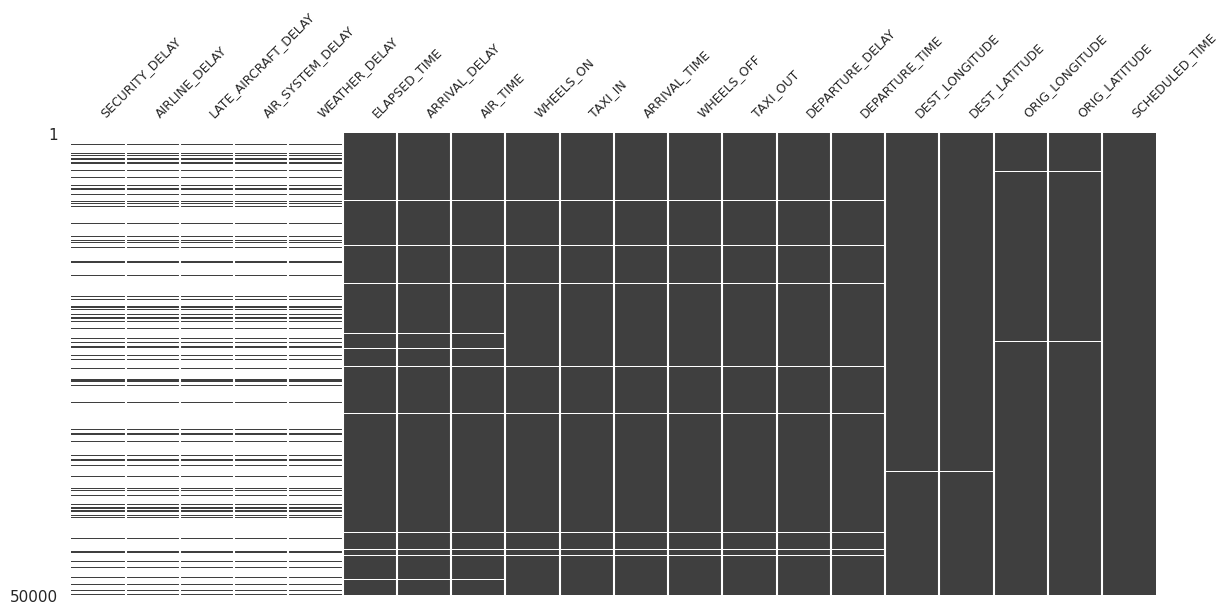

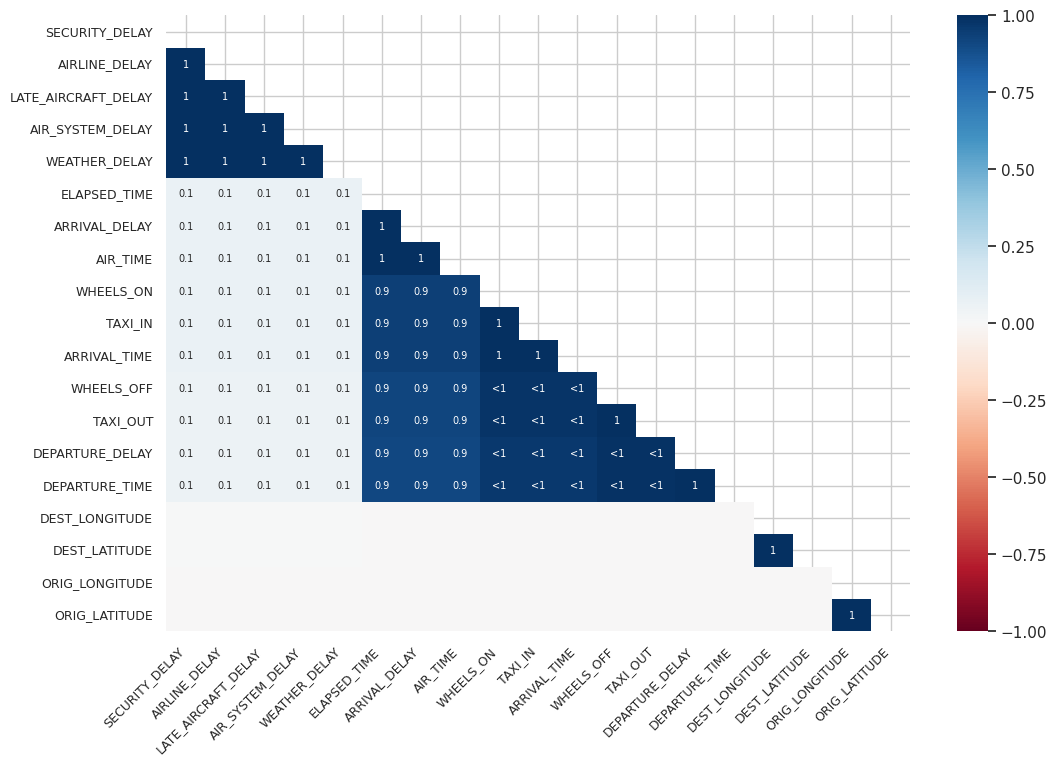

In [12]:
miss_sample = samp(df, 50_000)
msno.matrix(miss_sample[missing.index], figsize=(14, 6), fontsize=9, sparkline=False); plt.show()
msno.heatmap(miss_sample[missing.index], figsize=(12, 8), fontsize=9); plt.show()

In [13]:
flight_state = np.select([df["CANCELLED"] == 1, df["DIVERTED"] == 1], ["Cancelled", "Diverted"], "Completed")
(df[missing.index].isna().groupby(flight_state).mean().mul(100).round(1).T
   .style.background_gradient(cmap="Reds").format("{:.1f}%"))

,Cancelled,Completed,Diverted
SECURITY_DELAY,100.0%,80.8%,100.0%
AIRLINE_DELAY,100.0%,80.8%,100.0%
LATE_AIRCRAFT_DELAY,100.0%,80.8%,100.0%
AIR_SYSTEM_DELAY,100.0%,80.8%,100.0%
WEATHER_DELAY,100.0%,80.8%,100.0%
ELAPSED_TIME,100.0%,0.0%,100.0%
ARRIVAL_DELAY,100.0%,0.0%,100.0%
AIR_TIME,100.0%,0.0%,100.0%
WHEELS_ON,100.0%,0.0%,17.6%
TAXI_IN,100.0%,0.0%,17.6%


## 6. Cleaning & outliers

In [14]:
df["FLIGHT_DATE"] = pd.to_datetime(pd.DataFrame({"year": df["YEAR"], "month": df["MONTH"], "day": df["DAY"]}))

def hhmm_to_minutes(s):
    s = s.astype("float64")
    return (s // 100 % 24) * 60 + s % 100

for c in ["SCHEDULED_DEPARTURE", "DEPARTURE_TIME", "WHEELS_OFF", "WHEELS_ON", "SCHEDULED_ARRIVAL", "ARRIVAL_TIME"]:
    df[f"{c}_MIN"] = hhmm_to_minutes(df[c]).astype("float32")
df["SCHED_DEP_DT"] = df["FLIGHT_DATE"] + pd.to_timedelta(df["SCHEDULED_DEPARTURE_MIN"], unit="m")

df["STATUS"] = pd.Categorical(np.select([df["CANCELLED"] == 1, df["DIVERTED"] == 1], ["Cancelled", "Diverted"], "Completed"))
reason_map = {"A": "Airline/Carrier", "B": "Weather", "C": "National Air System", "D": "Security"}
df["CANCELLATION_REASON"] = df["CANCELLATION_REASON"].astype(str).map(reason_map).astype("category")

CAUSES = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]
done = df["STATUS"] == "Completed"
df.loc[done, CAUSES] = df.loc[done, CAUSES].fillna(0)

key = ["FLIGHT_DATE", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE"]
dups = df.duplicated(subset=key).sum()
df = df.drop_duplicates(subset=key)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=const_cols)
print(f"Duplicates removed: {dups:,} | constant columns dropped: {const_cols}")

Duplicates removed: 0 | constant columns dropped: ['YEAR', 'ORIG_COUNTRY', 'DEST_COUNTRY']


In [15]:
c = df.loc[done]
checks = {
    "AIR_TIME <= ELAPSED_TIME": (c["AIR_TIME"] <= c["ELAPSED_TIME"]).mean(),
    "ELAPSED = AIR + TAXI_IN + TAXI_OUT": np.isclose(c["ELAPSED_TIME"], c["AIR_TIME"] + c["TAXI_IN"] + c["TAXI_OUT"]).mean(),
    "delay causes sum = ARRIVAL_DELAY (when ≥15)": np.isclose(c.loc[c["ARRIVAL_DELAY"] >= 15, CAUSES].sum(axis=1),
                                                              c.loc[c["ARRIVAL_DELAY"] >= 15, "ARRIVAL_DELAY"]).mean(),
}
pd.Series(checks, name="share_consistent").map("{:.2%}".format).to_frame()

,share_consistent
AIR_TIME <= ELAPSED_TIME,100.00%
ELAPSED = AIR + TAXI_IN + TAXI_OUT,100.00%
delay causes sum = ARRIVAL_DELAY (when ≥15),100.00%


In [16]:
num_check = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "AIR_TIME", "DISTANCE"]
rows = []
for col in num_check:
    x = df[col].dropna().to_numpy(dtype="float64")
    q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
    rows.append({"column": col, "Q1": q1, "median": np.median(x), "Q3": q3,
                 "IQR_outlier_%": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100,
                 "z>3_%": (np.abs(stats.zscore(x)) > 3).mean() * 100,
                 "max": x.max(), "skew": stats.skew(x), "kurtosis": stats.kurtosis(x)})
pd.DataFrame(rows).set_index("column")

,Q1,median,Q3,IQR_outlier_%,z>3_%,max,skew,kurtosis
column,,,,,,,,
DEPARTURE_DELAY,-5.000,-1.000,8.000,12.542,2.040,"1,988.000",7.440,119.049
ARRIVAL_DELAY,-13.000,-5.000,8.000,9.295,1.956,"1,971.000",6.389,95.030
TAXI_OUT,11.000,14.000,19.000,5.026,1.692,225.000,3.492,24.016
TAXI_IN,4.000,6.000,9.000,4.958,1.817,248.000,5.212,60.551
AIR_TIME,60.000,94.000,144.000,5.184,1.273,690.000,1.377,2.098
DISTANCE,373.000,649.000,"1,065.000",5.998,0.643,"4,983.000",1.422,2.256


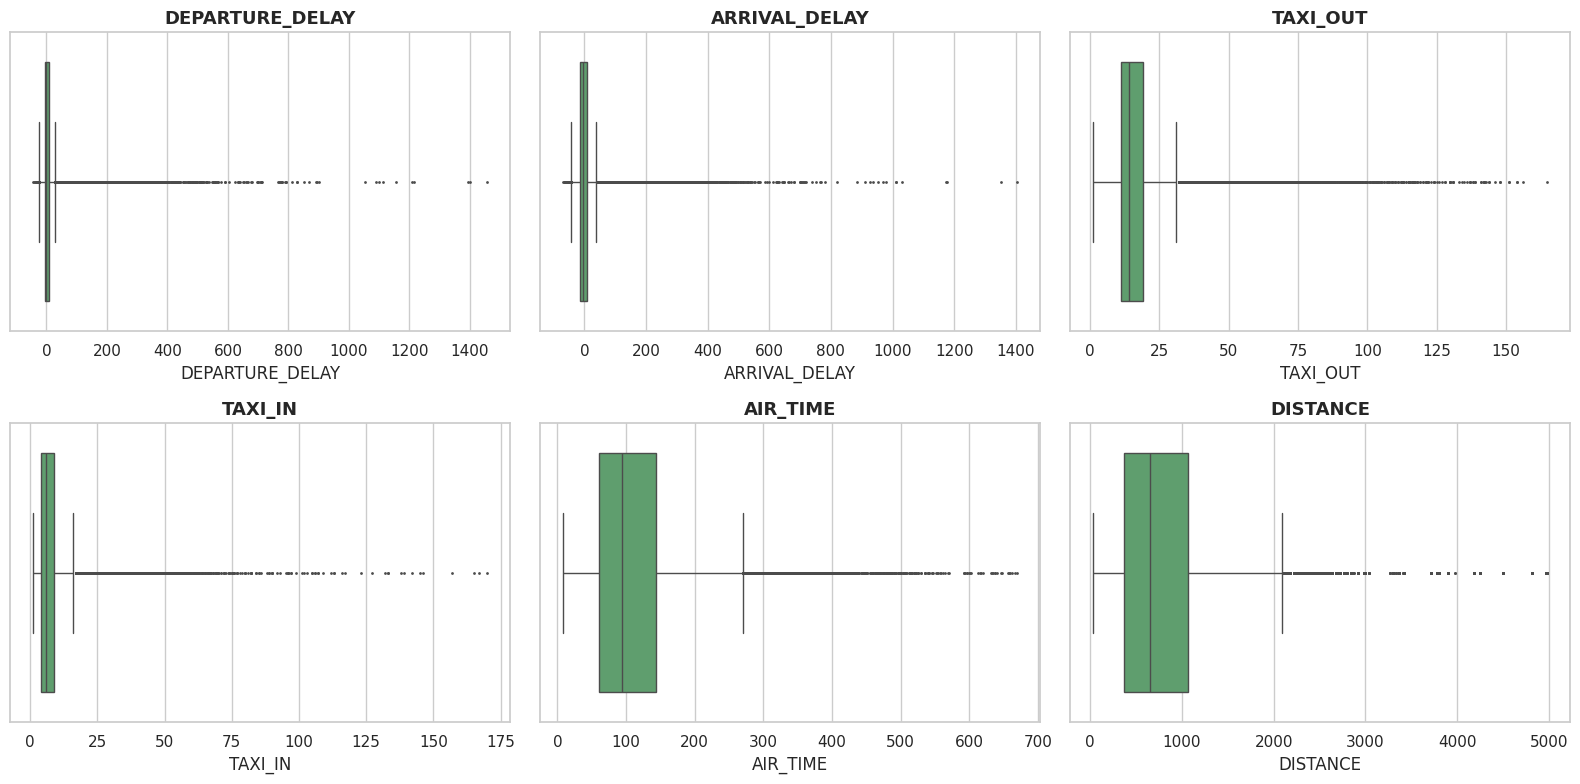

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_check):
    sns.boxplot(x=samp(df[col].dropna(), 200_000), ax=ax, color="#55A868", fliersize=1)
    ax.set_title(col)
plt.tight_layout(); plt.show()

df["ARR_DELAY_CAPPED"] = df["ARRIVAL_DELAY"].clip(-60, df["ARRIVAL_DELAY"].quantile(.995))
df["DEP_DELAY_CAPPED"] = df["DEPARTURE_DELAY"].clip(-60, df["DEPARTURE_DELAY"].quantile(.995))

## 7. Feature engineering

In [18]:
df["DEP_HOUR"] = (df["SCHEDULED_DEPARTURE"] // 100 % 24).astype("int8")
df["ARR_HOUR"] = (df["SCHEDULED_ARRIVAL"] // 100 % 24).astype("int8")
df["DEP_PERIOD"] = pd.cut(df["DEP_HOUR"], [-1, 5, 11, 17, 23], labels=["Night", "Morning", "Afternoon", "Evening"])
df["DAY_NAME"] = pd.Categorical(df["FLIGHT_DATE"].dt.day_name(),
                                ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
df["IS_WEEKEND"] = df["DAY_OF_WEEK"] >= 6
df["WEEK"] = df["FLIGHT_DATE"].dt.isocalendar().week.astype("int8")
df["DAY_OF_YEAR"] = df["FLIGHT_DATE"].dt.dayofyear.astype("int16")
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
df["SEASON"] = pd.Categorical(df["MONTH"].map(season_map), ["Winter", "Spring", "Summer", "Fall"], ordered=True)

holidays = USFederalHolidayCalendar().holidays("2014-12-01", "2016-01-31").to_numpy()
day_vals = df["FLIGHT_DATE"].to_numpy()
pos = np.searchsorted(holidays, day_vals)
prev_h, next_h = holidays[np.clip(pos - 1, 0, len(holidays) - 1)], holidays[np.clip(pos, 0, len(holidays) - 1)]
df["DAYS_TO_HOLIDAY"] = np.minimum(np.abs((day_vals - prev_h).astype("timedelta64[D]").astype(int)),
                                   np.abs((next_h - day_vals).astype("timedelta64[D]").astype(int))).astype("int16")

df["ROUTE"] = (df["ORIGIN_AIRPORT"].astype(str) + "→" + df["DESTINATION_AIRPORT"].astype(str)).astype("category")
df["DELAYED_15"] = (df["ARRIVAL_DELAY"] >= 15).astype("float32").where(df["STATUS"] == "Completed")
df["AVG_SPEED_MPH"] = (df["DISTANCE"] / df["AIR_TIME"] * 60).where(df["AIR_TIME"] > 0)
df["DISTANCE_BAND"] = pd.cut(df["DISTANCE"], [0, 500, 1000, 2000, 5000], labels=["<500 mi", "500-1000", "1000-2000", ">2000"])
df["TIME_MADE_UP"] = df["DEPARTURE_DELAY"] - df["ARRIVAL_DELAY"]

ad = df["ARRIVAL_DELAY"].to_numpy()
df["DELAY_CLASS"] = pd.Categorical(np.select([np.isnan(ad), ad < 0, ad < 15, ad < 60, ad < 180],
                                             ["Not arrived", "Early", "On time", "Moderate", "Long"], "Very long"),
                                   ["Early", "On time", "Moderate", "Long", "Very long", "Not arrived"], ordered=True)

cause_vals = df[CAUSES].fillna(0).to_numpy()
main = np.array([c.replace("_DELAY", "").replace("_", " ").title() for c in CAUSES])[cause_vals.argmax(axis=1)]
df["MAIN_CAUSE"] = pd.Categorical(np.where(df["DELAYED_15"] == 1, main, "None"))

df[["FLIGHT_DATE", "DEP_HOUR", "DEP_PERIOD", "DAY_NAME", "SEASON", "DAYS_TO_HOLIDAY", "ROUTE",
    "DELAYED_15", "AVG_SPEED_MPH", "DELAY_CLASS", "MAIN_CAUSE"]].head()

,FLIGHT_DATE,DEP_HOUR,DEP_PERIOD,DAY_NAME,SEASON,DAYS_TO_HOLIDAY,ROUTE,DELAYED_15,AVG_SPEED_MPH,DELAY_CLASS,MAIN_CAUSE
0,2015-09-18,7,Morning,Friday,Fall,11,JFK→LAX,0.000,458.333,Early,None
1,2015-04-08,12,Afternoon,Wednesday,Spring,47,IAH→CLT,0.000,448.525,On time,None
2,2015-07-23,5,Night,Thursday,Summer,20,MLI→ORD,0.000,278.000,Early,None
3,2015-09-14,15,Afternoon,Monday,Fall,7,LAS→IAD,0.000,516.250,Early,None
4,2015-07-09,10,Morning,Thursday,Summer,6,ATL→GRK,0.000,467.767,Early,None


## 8. NumPy

In [19]:
geo_ok = df[["ORIG_LATITUDE", "ORIG_LONGITUDE", "DEST_LATITUDE", "DEST_LONGITUDE"]].notna().all(axis=1).to_numpy()
lat1, lon1, lat2, lon2 = (np.radians(df.loc[geo_ok, c].to_numpy(dtype="float64"))
                          for c in ["ORIG_LATITUDE", "ORIG_LONGITUDE", "DEST_LATITUDE", "DEST_LONGITUDE"])

def haversine_mi(lat1, lon1, lat2, lon2):
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

t = time.time(); gc_dist = haversine_mi(lat1, lon1, lat2, lon2); t_np = time.time() - t
df.loc[geo_ok, "GREAT_CIRCLE_MI"] = gc_dist.astype("float32")

n = min(200_000, len(gc_dist))
t = time.time()
_ = [3958.8 * 2 * math.asin(math.sqrt(math.sin((lat2[i] - lat1[i]) / 2) ** 2 +
     math.cos(lat1[i]) * math.cos(lat2[i]) * math.sin((lon2[i] - lon1[i]) / 2) ** 2)) for i in range(n)]
t_loop = (time.time() - t) * len(gc_dist) / max(n, 1)
reported = df.loc[geo_ok, "DISTANCE"].to_numpy(dtype="float64")
print(f"NumPy {t_np:.3f}s vs estimated Python loop {t_loop:.1f}s → ~{t_loop / max(t_np, 1e-9):,.0f}× faster")
print(f"Correlation reported vs great-circle distance: {np.corrcoef(reported, gc_dist)[0, 1]:.4f}")
print(f"Median ratio reported / great-circle: {np.median(reported / np.maximum(gc_dist, 1)):.3f}")

NumPy 0.311s vs estimated Python loop 7.6s → ~24× faster
Correlation reported vs great-circle distance: 0.9985
Median ratio reported / great-circle: 1.001


In [20]:
arr = df["ARRIVAL_DELAY"].dropna().to_numpy(dtype="float64")
dep = df["DEPARTURE_DELAY"].dropna().to_numpy(dtype="float64")
print("Arrival delay percentiles (5,25,50,75,95,99):", np.percentile(arr, [5, 25, 50, 75, 95, 99]).round(1))
print(f"Mean {arr.mean():.2f} | std {arr.std():.2f} | trimmed mean (10%) {stats.trim_mean(arr, .1):.2f}")
print(f"Arrived early: {(arr < 0).mean():.1%} | on time (<15): {(arr < 15).mean():.1%} | over 3 hours late: {(arr >= 180).mean():.2%}")

X = df[["DEPARTURE_DELAY", "TAXI_OUT", "AIR_TIME", "TAXI_IN", "ARRIVAL_DELAY"]].dropna().to_numpy(dtype="float64")
Z = (X - X.mean(axis=0)) / X.std(axis=0)
print("Standardised means:", Z.mean(axis=0).round(6), "| stds:", Z.std(axis=0).round(3))
display(pd.DataFrame(np.corrcoef(Z, rowvar=False), index=["DEP", "TAXI_OUT", "AIR", "TAXI_IN", "ARR"],
                     columns=["DEP", "TAXI_OUT", "AIR", "TAXI_IN", "ARR"]).round(3))

counts, edges = np.histogram(arr, bins=[-np.inf, -15, 0, 15, 60, 180, np.inf])
labels = ["< -15", "-15..0", "0..15", "15..60", "60..180", "> 180"]
print("Arrival delay bins:", dict(zip(labels, counts.tolist())))
codes, cnts = np.unique(df["AIRLINE"].astype(str).to_numpy(), return_counts=True)
print("Flights per airline code:", dict(zip(codes.tolist(), cnts.tolist())))

Arrival delay percentiles (5,25,50,75,95,99): [-25. -13.  -5.   8.  68. 169.]
Mean 4.89 | std 39.79 | trimmed mean (10%) -2.10
Arrived early: 60.6% | on time (<15): 80.8% | over 3 hours late: 0.87%
Standardised means: [-0.  0. -0.  0. -0.] | stds: [1. 1. 1. 1. 1.]


,DEP,TAXI_OUT,AIR,TAXI_IN,ARR
DEP,1.000,0.060,0.023,0.013,0.945
TAXI_OUT,0.060,1.000,0.088,0.004,0.228
AIR,0.023,0.088,1.000,0.081,-0.006
TAXI_IN,0.013,0.004,0.081,1.000,0.117
ARR,0.945,0.228,-0.006,0.117,1.000


Arrival delay bins: {'< -15': 744141, '-15..0': 1633662, '0..15': 793068, '15..60': 520388, '60..180': 198276, '> 180': 33942}
Flights per airline code: {'AA': 486473, 'AS': 118571, 'B6': 183994, 'DL': 600010, 'EV': 394361, 'F9': 61854, 'HA': 52619, 'MQ': 204554, 'NK': 80401, 'OO': 404730, 'UA': 352759, 'US': 149510, 'VX': 42309, 'WN': 867855}


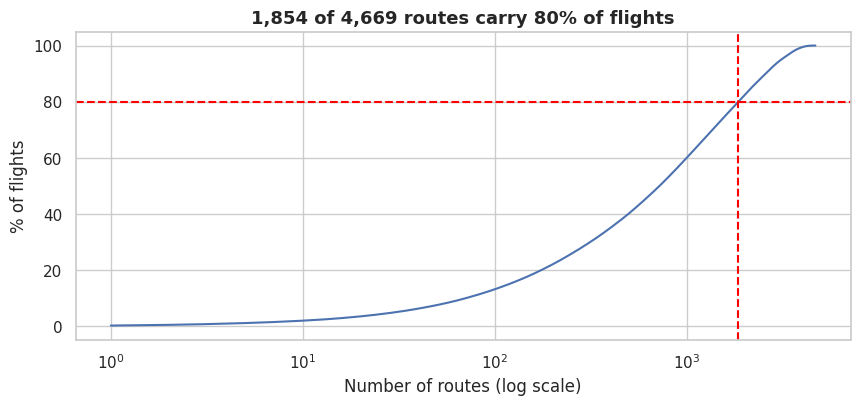

In [21]:
route_counts = np.sort(df["ROUTE"].value_counts().to_numpy())[::-1]
cum_share = np.cumsum(route_counts) / route_counts.sum()
n80 = int(np.searchsorted(cum_share, .8)) + 1
plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, len(cum_share) + 1), cum_share * 100)
plt.axhline(80, ls="--", c="red"); plt.axvline(n80, ls="--", c="red")
plt.xscale("log"); plt.xlabel("Number of routes (log scale)"); plt.ylabel("% of flights")
plt.title(f"{n80:,} of {len(route_counts):,} routes carry 80% of flights"); plt.show()

## 9. Advanced pandas

In [22]:
airline_stats = (df.groupby("AIRLINE_NAME", observed=True)
                   .agg(flights=("FLIGHT_NUMBER", "size"),
                        on_time_rate=("DELAYED_15", lambda s: 1 - s.mean()),
                        mean_arr_delay=("ARRIVAL_DELAY", "mean"),
                        median_arr_delay=("ARRIVAL_DELAY", "median"),
                        cancel_rate=("CANCELLED", "mean"),
                        divert_rate=("DIVERTED", "mean"),
                        avg_distance=("DISTANCE", "mean"),
                        avg_taxi_out=("TAXI_OUT", "mean"),
                        routes=("ROUTE", "nunique"),
                        aircraft=("TAIL_NUMBER", "nunique"))
                   .sort_values("flights", ascending=False))
airline_stats["share_%"] = airline_stats["flights"] / airline_stats["flights"].sum() * 100
airline_stats["flights_per_aircraft"] = airline_stats["flights"] / airline_stats["aircraft"]
airline_stats["punctuality_rank"] = airline_stats["on_time_rate"].rank(ascending=False).astype(int)
airline_stats.style.background_gradient(subset=["on_time_rate"], cmap="RdYlGn").background_gradient(
    subset=["cancel_rate", "mean_arr_delay"], cmap="Reds").format(precision=3)

,flights,on_time_rate,mean_arr_delay,median_arr_delay,cancel_rate,divert_rate,avg_distance,avg_taxi_out,routes,aircraft,share_%,flights_per_aircraft,punctuality_rank
AIRLINE_NAME,,,,,,,,,,,,,
Southwest Airlines Co.,867855,0.803,4.839,-4.000,0.014,0.003,741.266,11.955,1333,705,21.696,1231.000,8
Delta Air Lines Inc.,600010,0.859,0.677,-7.000,0.005,0.002,855.562,17.694,942,825,15.000,727.285,3
American Airlines Inc.,486473,0.812,3.931,-6.000,0.016,0.003,1046.994,17.760,705,1044,12.162,465.970,5
Skywest Airlines Inc.,404730,0.808,6.259,-4.000,0.018,0.003,496.277,18.146,1318,384,10.118,1053.984,6
Atlantic Southeast Airlines,394361,0.799,6.961,-4.000,0.028,0.003,462.997,16.754,1386,391,9.859,1008.596,9
United Air Lines Inc.,352759,0.785,6.157,-5.000,0.014,0.003,1275.246,17.445,693,721,8.819,489.264,10
American Eagle Airlines Inc.,204554,0.774,7.293,-5.000,0.054,0.003,424.447,16.613,426,204,5.114,1002.716,11
JetBlue Airways,183994,0.771,6.932,-5.000,0.017,0.003,1062.142,17.948,340,215,4.600,855.786,12
US Airways Inc.,149510,0.812,3.706,-4.000,0.020,0.002,911.269,18.981,336,352,3.738,424.744,4


In [23]:
pivot_am = df.pivot_table(index="AIRLINE", columns="MONTH", values="ARRIVAL_DELAY", aggfunc="mean", observed=True).round(1)
display(pivot_am.style.background_gradient(cmap="RdYlGn_r", axis=None).format("{:.1f}"))

display(pd.crosstab(df["MONTH"], df["CANCELLATION_REASON"], normalize="index").mul(100).round(1))

multi = df.groupby(["SEASON", "DEP_PERIOD"], observed=True)["DELAYED_15"].mean().unstack().mul(100).round(1)
display(multi)
display(multi.stack().rename("delayed_%").reset_index().head(8))

MONTH,1,2,3,4,5,6,7,8,9,11,12
AIRLINE,,,,,,,,,,,
AA,6.7,7.2,6.5,5.2,5.1,8.3,4.0,3.2,-1.4,0.7,4.2
AS,-0.4,-0.6,-0.6,-3.1,-1.6,-0.1,0.5,2.6,-1.8,-1.7,-1.9
B6,7.6,18.5,10.7,2.7,-0.7,5.1,5.7,9.1,3.7,1.2,14.0
DL,-2.0,5.7,2.1,0.0,0.1,4.2,1.2,0.6,-3.7,-3.0,2.6
EV,8.5,10.6,6.8,4.8,7.5,13.9,6.9,5.3,0.9,4.3,6.8
F9,18.0,28.3,20.2,13.1,13.1,19.7,13.9,9.1,0.9,11.0,9.5
HA,3.4,6.2,3.4,0.1,0.8,0.9,2.2,7.4,3.7,-2.6,-1.8
MQ,18.0,21.5,10.9,5.2,5.3,9.6,4.0,2.0,-2.3,0.2,0.8
NK,11.4,16.1,10.1,8.8,22.8,35.6,14.1,20.7,8.2,7.5,13.0


CANCELLATION_REASON,Airline/Carrier,National Air System,Security,Weather
MONTH,,,,
1,23.500,17.600,0.000,58.900
2,13.800,11.100,0.000,75.100
3,22.400,15.200,0.000,62.300
4,40.000,20.300,0.000,39.600
5,34.800,15.900,0.000,49.300
6,39.500,23.800,0.000,36.600
7,53.500,27.700,0.000,18.800
8,46.800,27.000,0.100,26.100
9,51.700,23.500,0.000,24.800


DEP_PERIOD,Night,Morning,Afternoon,Evening
SEASON,,,,
Winter,12.300,16.700,23.900,27.200
Spring,8.800,12.900,20.800,24.600
Summer,8.300,13.000,24.300,31.200
Fall,6.800,10.100,16.100,19.000


,SEASON,DEP_PERIOD,delayed_%
0,Winter,Night,12.300
1,Winter,Morning,16.700
2,Winter,Afternoon,23.900
3,Winter,Evening,27.200
4,Spring,Night,8.800
5,Spring,Morning,12.900
6,Spring,Afternoon,20.800
7,Spring,Evening,24.600


In [24]:
cause_long = (df.loc[df["DELAYED_15"] == 1, ["AIRLINE"] + CAUSES]
                .melt(id_vars="AIRLINE", var_name="cause", value_name="minutes"))
cause_share = (cause_long.groupby(["AIRLINE", "cause"], observed=True)["minutes"].sum()
                         .groupby(level=0, group_keys=False).apply(lambda s: s / s.sum() * 100).unstack().round(1))
cause_share

cause,AIRLINE_DELAY,AIR_SYSTEM_DELAY,LATE_AIRCRAFT_DELAY,SECURITY_DELAY,WEATHER_DELAY
AIRLINE,,,,,
AA,34.900,22.300,36.500,0.200,6.100
AS,32.300,27.700,35.700,0.600,3.800
B6,29.400,27.300,39.800,0.300,3.300
DL,36.400,24.900,30.000,0.100,8.600
EV,34.300,24.600,38.500,0.000,2.600
F9,21.700,37.100,39.700,0.000,1.500
HA,57.200,1.500,37.600,0.100,3.500
MQ,27.200,24.600,37.300,0.200,10.700
NK,22.800,41.100,33.700,0.300,2.200


In [25]:
df["ROUTE_MEAN_DELAY"] = df.groupby("ROUTE", observed=True)["ARRIVAL_DELAY"].transform("mean")
df["DELAY_VS_ROUTE"] = df["ARRIVAL_DELAY"] - df["ROUTE_MEAN_DELAY"]
df["TAXI_OUT_Q"] = pd.qcut(df["TAXI_OUT"], 5, labels=["Q1 fast", "Q2", "Q3", "Q4", "Q5 slow"], duplicates="drop")

display(df.query("ARRIVAL_DELAY > 600 and DISTANCE < 500")
          [["FLIGHT_DATE", "AIRLINE_NAME", "ROUTE", "DEPARTURE_DELAY", "ARRIVAL_DELAY", "MAIN_CAUSE"]].head(8))

origin_stats = (df.groupby("ORIGIN_AIRPORT", observed=True)
                  .agg(departures=("FLIGHT_NUMBER", "size"), dep_delay=("DEPARTURE_DELAY", "mean"),
                       taxi_out=("TAXI_OUT", "mean"), cancel_rate=("CANCELLED", "mean"),
                       destinations=("DESTINATION_AIRPORT", "nunique"))
                  .reset_index()
                  .merge(ap, left_on="ORIGIN_AIRPORT", right_on="IATA_CODE", how="left")
                  .drop(columns="IATA_CODE")
                  .sort_values("departures", ascending=False))
display(origin_stats.head(15))

daily = (df.groupby("FLIGHT_DATE")
           .agg(flights=("FLIGHT_NUMBER", "size"), cancelled=("CANCELLED", "sum"),
                mean_arr_delay=("ARRIVAL_DELAY", "mean"), delayed_rate=("DELAYED_15", "mean")))
daily["ma_7"] = daily["mean_arr_delay"].rolling(7, min_periods=3).mean()
daily["ewm_14"] = daily["mean_arr_delay"].ewm(span=14).mean()
daily["cancel_rate"] = daily["cancelled"] / daily["flights"]
daily["flights_wow_%"] = daily["flights"].pct_change(7) * 100
daily.tail()

,FLIGHT_DATE,AIRLINE_NAME,ROUTE,DEPARTURE_DELAY,ARRIVAL_DELAY,MAIN_CAUSE
8448,2015-06-15,United Air Lines Inc.,MSP→ORD,563.000,621.000,Air System
37289,2015-02-25,American Airlines Inc.,MFE→DFW,"1,362.000","1,369.000",Airline
37458,2015-05-13,Delta Air Lines Inc.,PHL→DTW,897.000,888.000,Airline
80116,2015-02-01,Skywest Airlines Inc.,FAT→PHX,694.000,687.000,Weather
104413,2015-05-13,American Airlines Inc.,DFW→AUS,812.000,805.000,Airline
112971,2015-05-18,American Eagle Airlines Inc.,FWA→ORD,919.000,914.000,Airline
118395,2015-09-24,Skywest Airlines Inc.,MSP→BRD,878.000,872.000,Airline
121480,2015-06-10,Skywest Airlines Inc.,FWA→ORD,680.000,681.000,Airline


,ORIGIN_AIRPORT,departures,dep_delay,taxi_out,cancel_rate,destinations,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
20,ATL,259983,9.299,17.407,0.007,169,Hartsfield-Jackson Atlanta International Airport,Atlanta,GA,USA,33.640,-84.427
228,ORD,214493,14.144,19.540,0.030,162,Chicago O'Hare International Airport,Chicago,IL,USA,41.980,-87.904
86,DFW,179567,11.542,17.241,0.026,148,Dallas/Fort Worth International Airport,Dallas-Fort Worth,TX,USA,32.896,-97.037
85,DEN,146922,11.878,15.971,0.011,139,Denver International Airport,Denver,CO,USA,39.858,-104.667
176,LAX,145961,10.712,16.958,0.011,80,Los Angeles International Airport,Los Angeles,CA,USA,33.943,-118.408
278,SFO,110874,11.274,17.755,0.014,79,San Francisco International Airport,San Francisco,CA,USA,37.619,-122.375
239,PHX,110259,8.622,15.301,0.006,79,Phoenix Sky Harbor International Airport,Phoenix,AZ,USA,33.434,-112.008
151,IAH,110062,11.554,17.800,0.015,119,George Bush Intercontinental Airport,Houston,TX,USA,29.980,-95.340
174,LAS,100054,10.941,14.719,0.007,78,McCarran International Airport,Las Vegas,NV,USA,36.080,-115.152
216,MSP,84033,7.290,17.481,0.007,120,Minneapolis-Saint Paul International Airport,Minneapolis,MN,USA,44.881,-93.217


,flights,cancelled,mean_arr_delay,delayed_rate,ma_7,ewm_14,cancel_rate,flights_wow_%
FLIGHT_DATE,,,,,,,,
2015-12-27,12378,870,28.196,0.396,14.642,10.716,0.070,4.052
2015-12-28,12209,1603,24.462,0.365,16.773,12.549,0.131,-0.098
2015-12-29,12128,530,26.029,0.395,18.677,14.346,0.044,-0.858
2015-12-30,12144,205,26.063,0.433,19.426,15.908,0.017,-2.238
2015-12-31,9809,36,1.074,0.157,17.246,13.930,0.004,-1.920


In [26]:
top_routes = (df.groupby(["AIRLINE", "ROUTE"], observed=True).size().rename("flights")
                .groupby(level=0, group_keys=False).nlargest(3).reset_index())
display(top_routes.head(15))
busiest_tails = (df.groupby(["TAIL_NUMBER", "AIRLINE"], observed=True).size().rename("flights")
                   .sort_values(ascending=False).head(10))
busiest_tails.to_frame()

,AIRLINE,ROUTE,flights
0,AA,LAX→DFW,4140
1,AA,DFW→LAX,4113
2,AA,DFW→ORD,4028
3,AS,SEA→ANC,3735
4,AS,ANC→SEA,3698
5,AS,LAX→SEA,3492
6,B6,JFK→MCO,2364
7,B6,MCO→JFK,2328
8,B6,BOS→DCA,2318
9,DL,LGA→ATL,3981


flights
TAIL_NUMBER AIRLINE         
None        UA          4570
            US          2890
N480HA      HA          2603
N488HA      HA          2571
N484HA      HA          2549
N493HA      HA          2506
N478HA      HA          2439
N483HA      HA          2408
N489HA      HA          2374
N487HA      HA          2365

## 10. Univariate analysis

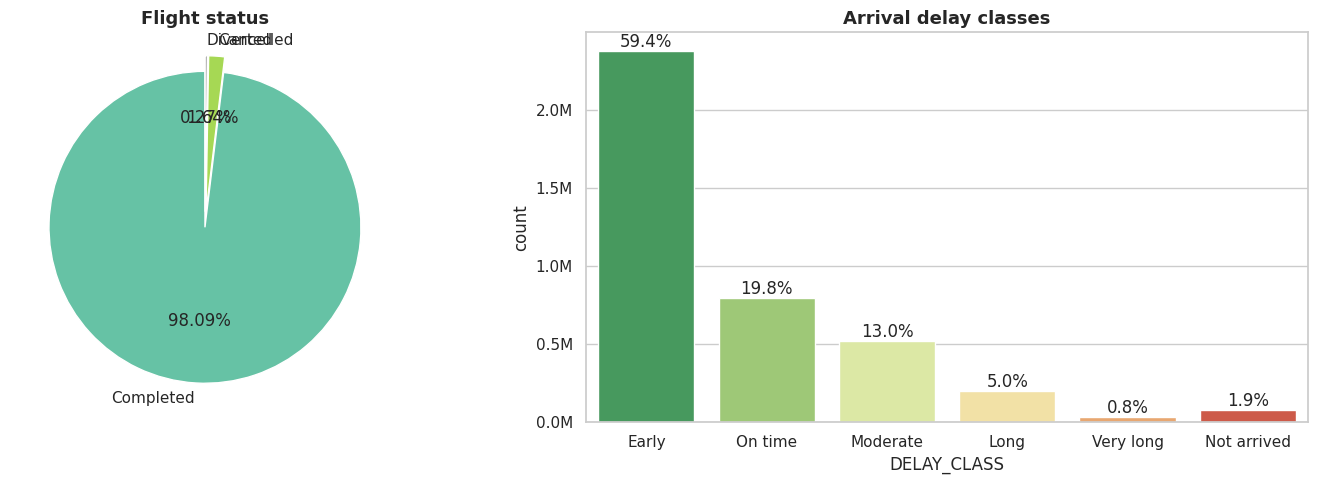

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df["STATUS"].value_counts().plot.pie(autopct="%1.2f%%", ax=axes[0], startangle=90, cmap="Set2", explode=[0, .1, .1])
axes[0].set(title="Flight status", ylabel="")
sns.countplot(x="DELAY_CLASS", data=df, ax=axes[1], palette="RdYlGn_r")
axes[1].set_title("Arrival delay classes")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height() / len(df):.1%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); savefig("status_delay_class"); plt.show()

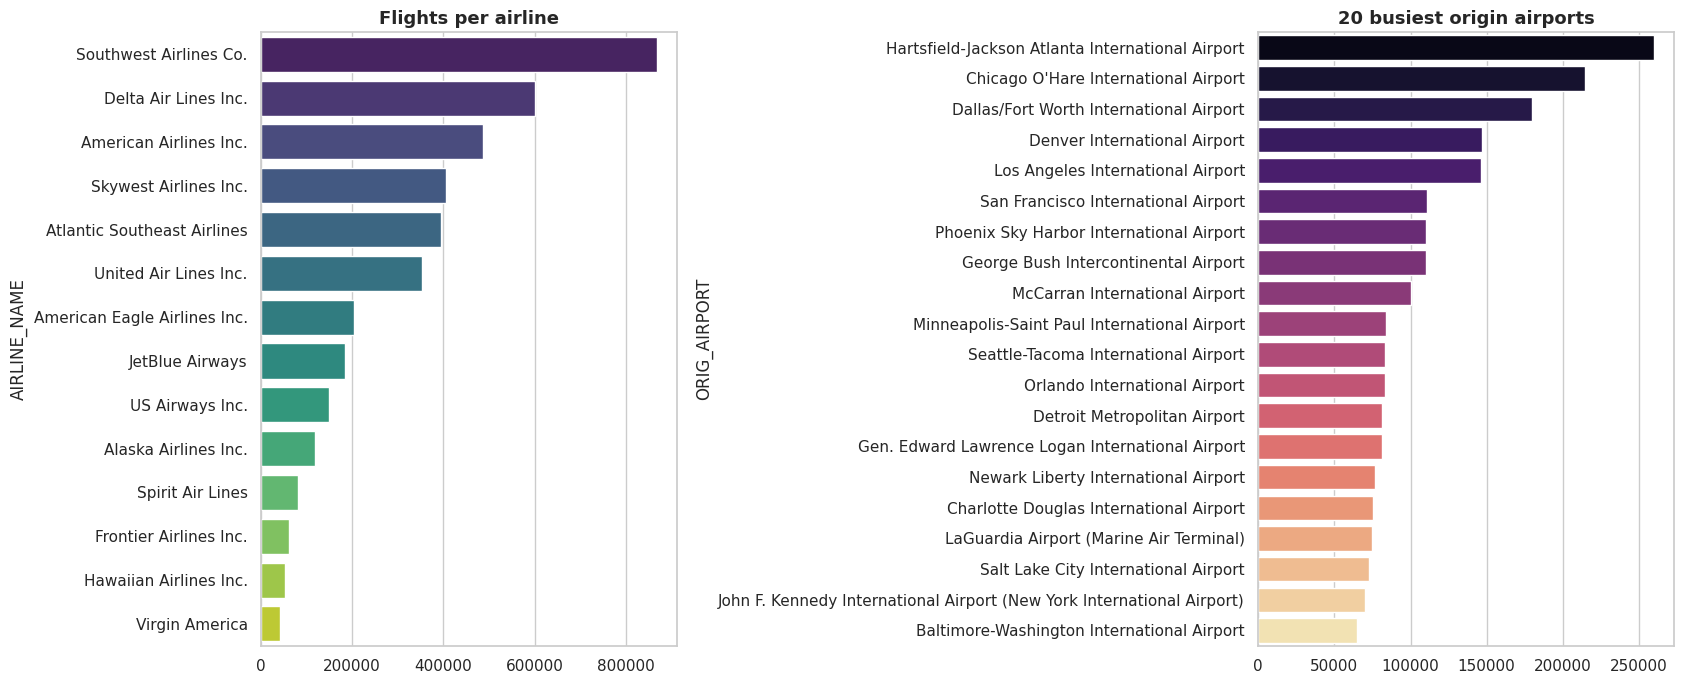

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
air = df["AIRLINE_NAME"].value_counts()
sns.barplot(x=air.values, y=air.index.astype(str), ax=axes[0], palette="viridis")
axes[0].set_title("Flights per airline")
busiest = df["ORIG_AIRPORT"].value_counts().head(20)
sns.barplot(x=busiest.values, y=busiest.index.astype(str), ax=axes[1], palette="magma")
axes[1].set_title("20 busiest origin airports")
plt.tight_layout(); savefig("airlines_airports"); plt.show()

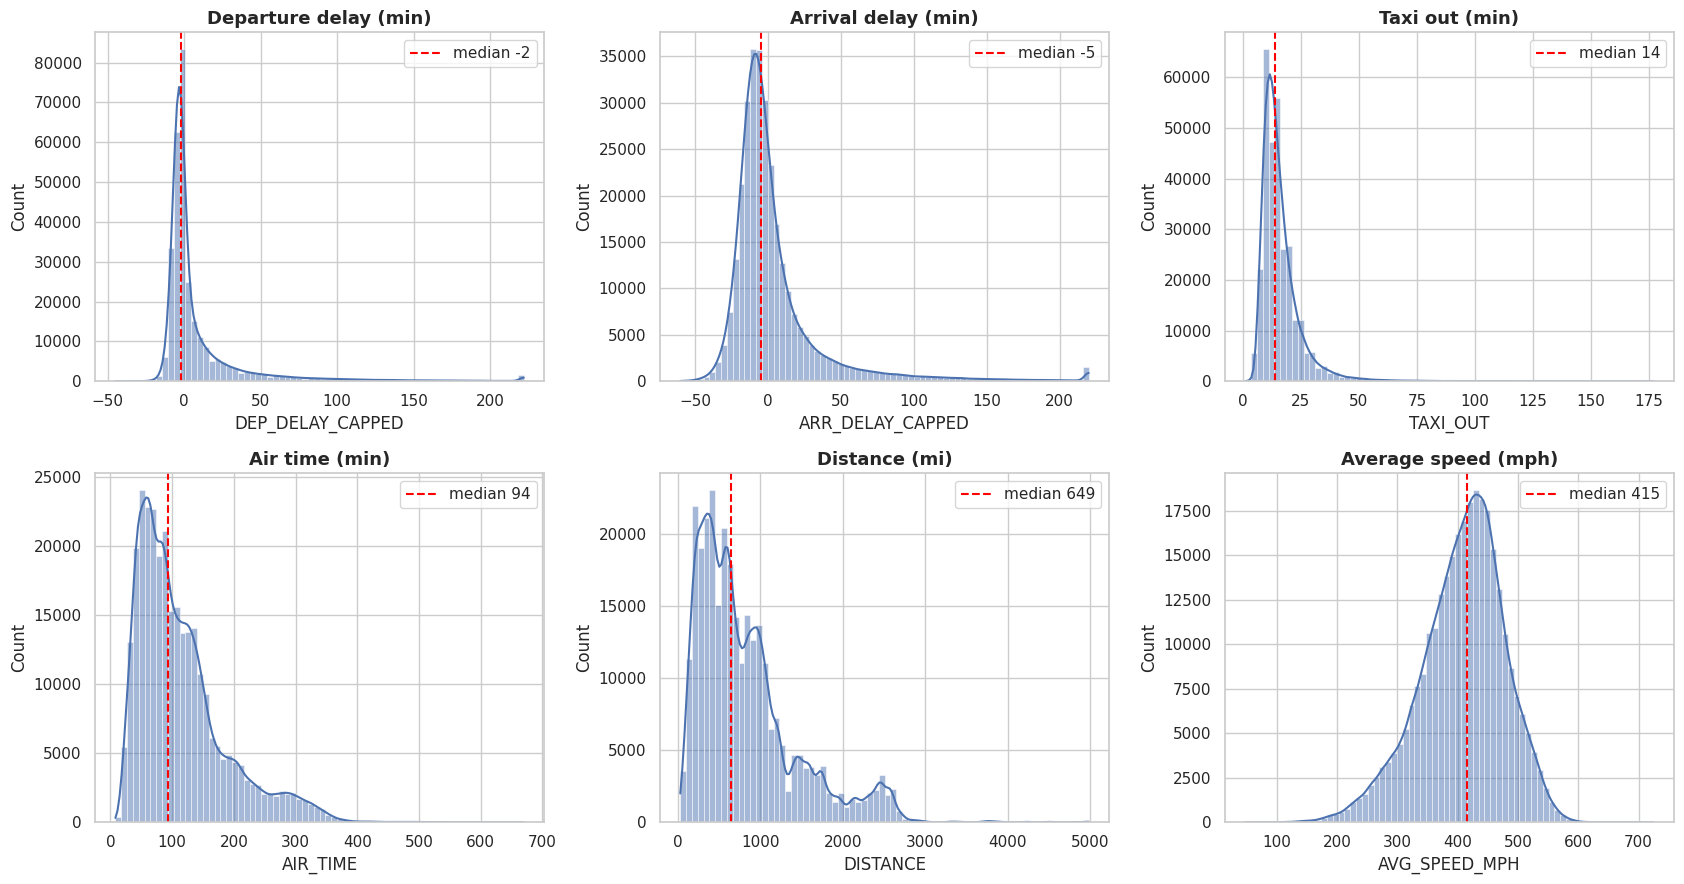

In [29]:
sample = samp(df.loc[df["STATUS"] == "Completed"], 300_000)
plots = [("DEP_DELAY_CAPPED", "Departure delay (min)"), ("ARR_DELAY_CAPPED", "Arrival delay (min)"),
         ("TAXI_OUT", "Taxi out (min)"), ("AIR_TIME", "Air time (min)"), ("DISTANCE", "Distance (mi)"),
         ("AVG_SPEED_MPH", "Average speed (mph)")]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, label) in zip(axes.flat, plots):
    data = sample[col].dropna()
    if "DELAY" in col:
        data = data[data.between(-60, 240)]
    sns.histplot(data, bins=70, kde=True, ax=ax, color="#4C72B0")
    ax.axvline(data.median(), color="red", ls="--", label=f"median {data.median():.0f}")
    ax.set_title(label); ax.legend()
plt.tight_layout(); savefig("numeric_distributions"); plt.show()

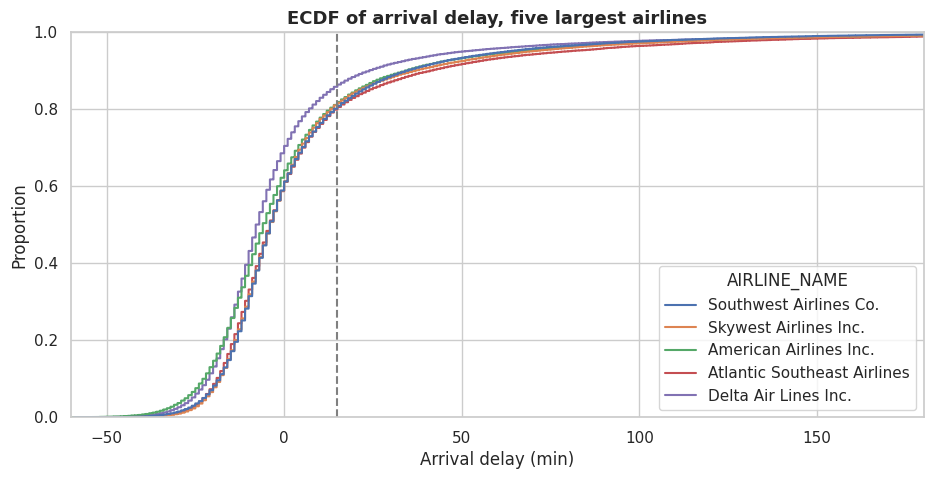

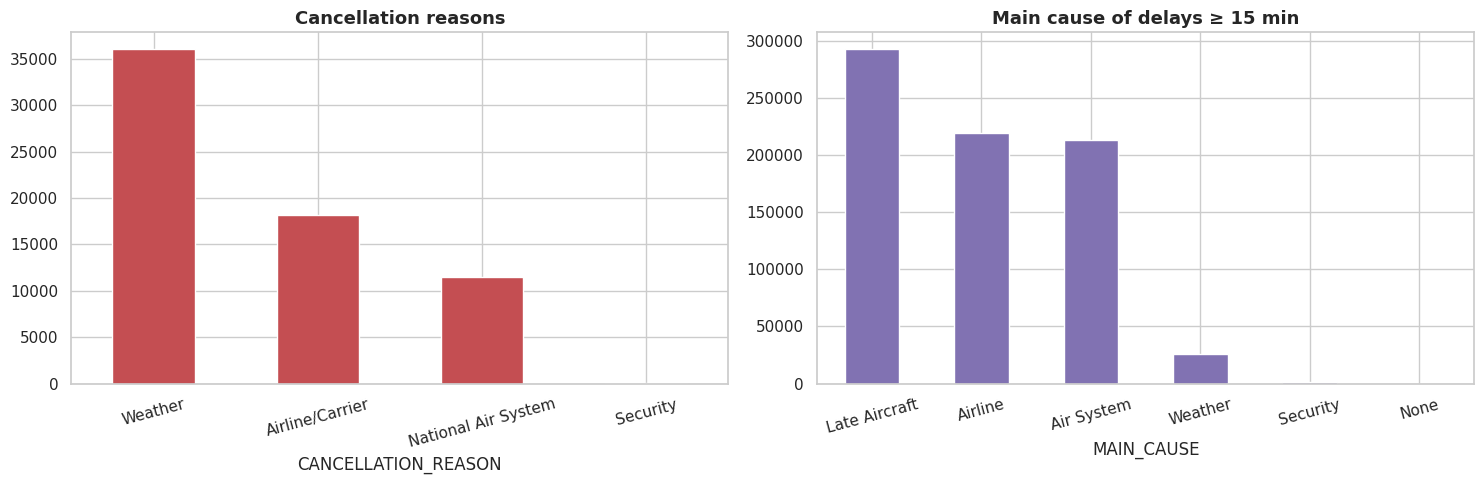

In [30]:
top5 = df["AIRLINE_NAME"].value_counts().index[:5]
plt.figure(figsize=(11, 5))
sns.ecdfplot(data=sample[sample["AIRLINE_NAME"].isin(top5)].assign(AIRLINE_NAME=lambda d: d["AIRLINE_NAME"].astype(str)),
             x="ARR_DELAY_CAPPED", hue="AIRLINE_NAME")
plt.axvline(15, ls="--", c="grey"); plt.xlim(-60, 180)
plt.title("ECDF of arrival delay, five largest airlines"); plt.xlabel("Arrival delay (min)"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df["CANCELLATION_REASON"].value_counts().plot.bar(ax=axes[0], color="#C44E52", rot=15, title="Cancellation reasons")
df.loc[df["MAIN_CAUSE"] != "None", "MAIN_CAUSE"].value_counts().plot.bar(ax=axes[1], color="#8172B2", rot=15,
                                                                         title="Main cause of delays ≥ 15 min")
plt.tight_layout(); plt.show()

## 11. Time analysis

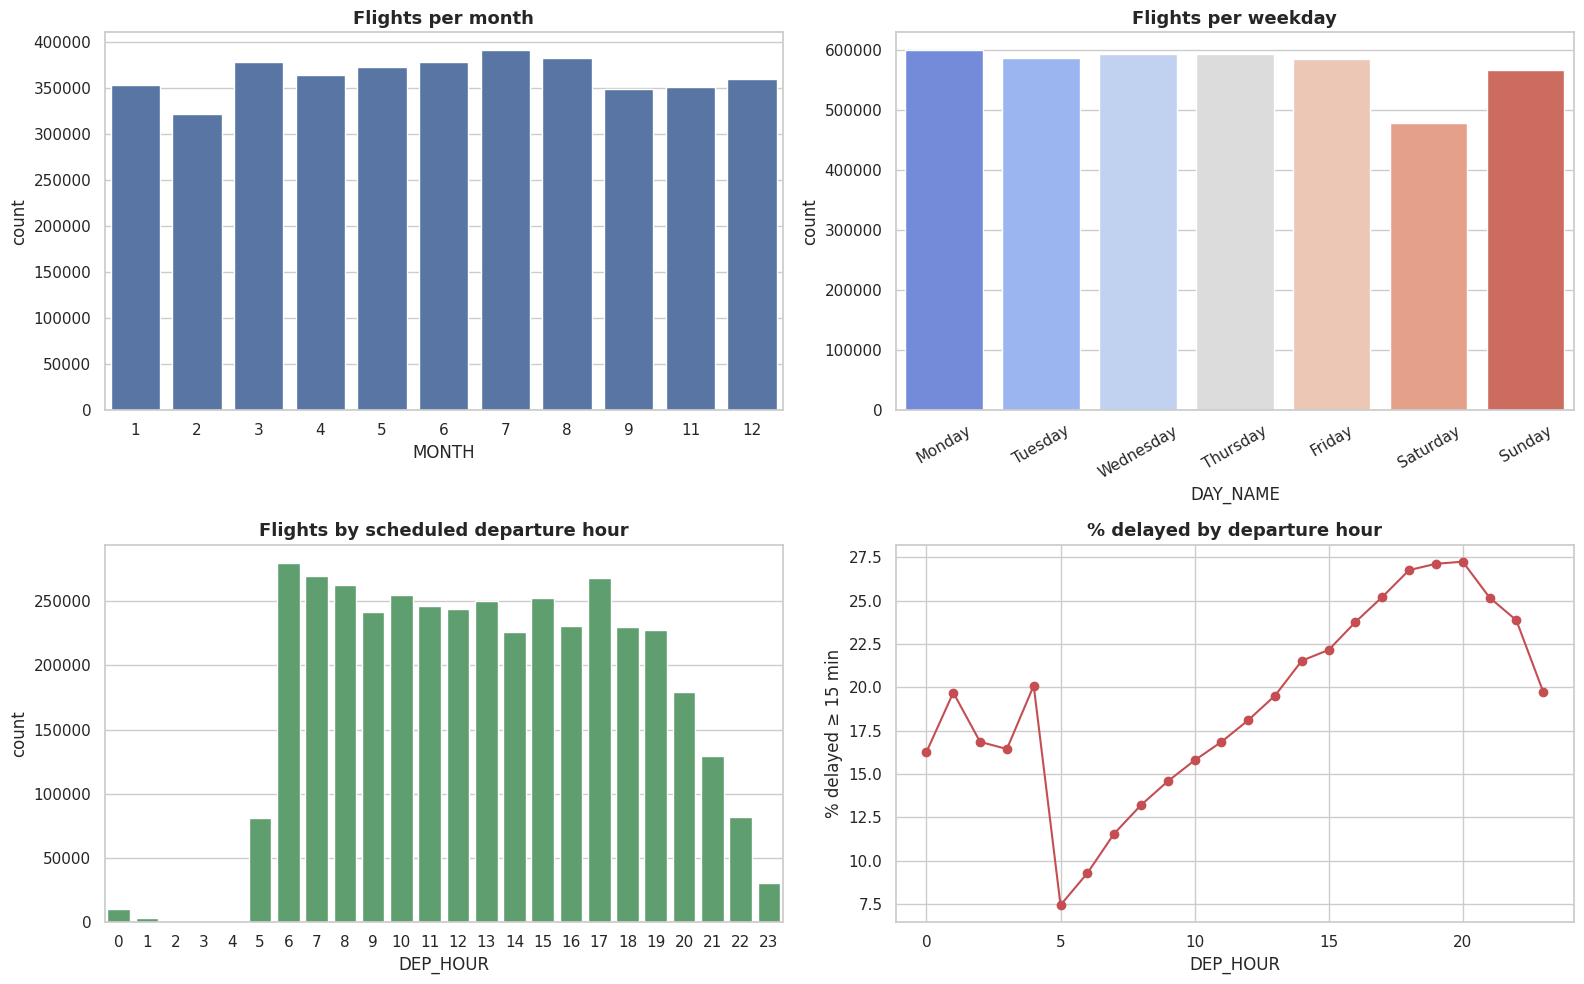

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.countplot(x="MONTH", data=df, ax=axes[0, 0], color="#4C72B0"); axes[0, 0].set_title("Flights per month")
sns.countplot(x="DAY_NAME", data=df, ax=axes[0, 1], palette="coolwarm"); axes[0, 1].set_title("Flights per weekday")
axes[0, 1].tick_params(axis="x", rotation=30)
sns.countplot(x="DEP_HOUR", data=df, ax=axes[1, 0], color="#55A868"); axes[1, 0].set_title("Flights by scheduled departure hour")
df.groupby("DEP_HOUR")["DELAYED_15"].mean().mul(100).plot(ax=axes[1, 1], marker="o", color="#C44E52")
axes[1, 1].set(title="% delayed by departure hour", ylabel="% delayed ≥ 15 min")
plt.tight_layout(); savefig("time_counts"); plt.show()

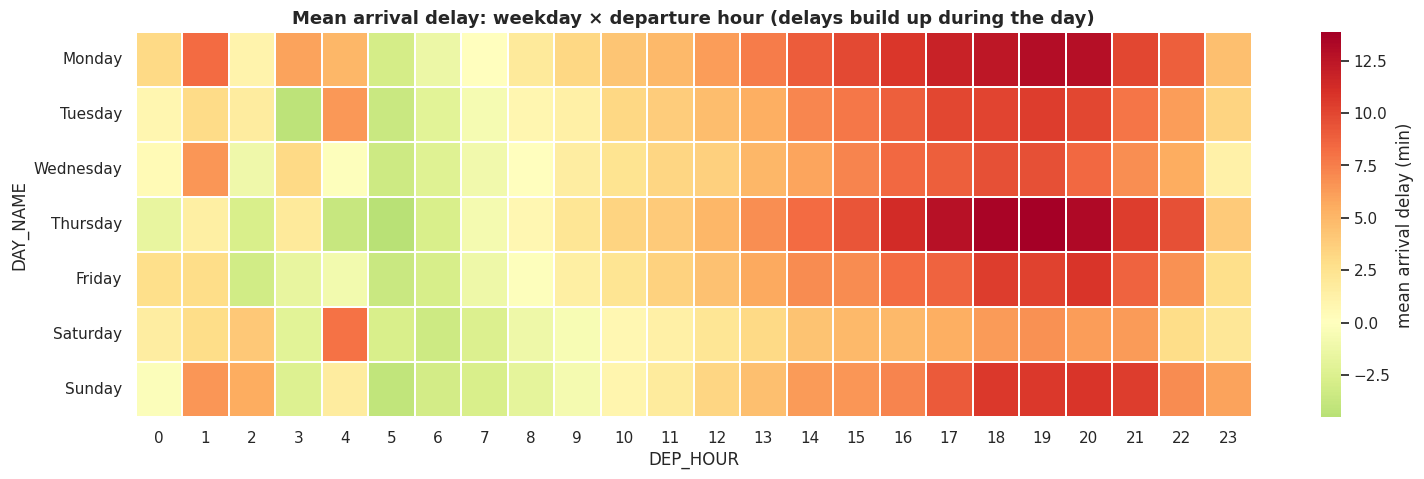

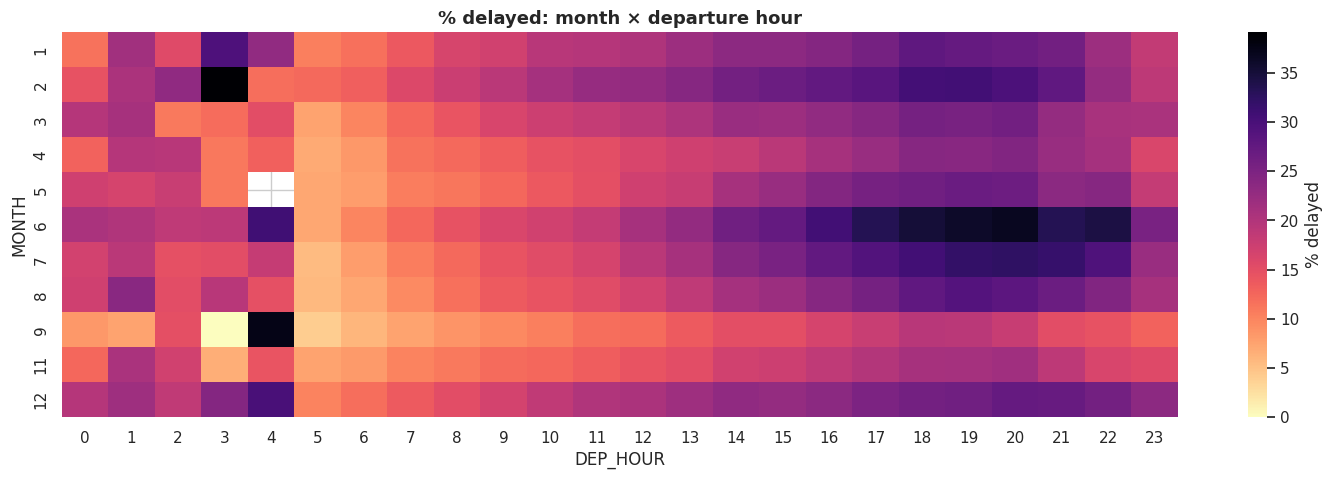

In [32]:
heat = df.pivot_table(index="DAY_NAME", columns="DEP_HOUR", values="ARRIVAL_DELAY", aggfunc="mean", observed=True)
plt.figure(figsize=(18, 5))
sns.heatmap(heat, cmap="RdYlGn_r", center=0, linewidths=.3, cbar_kws={"label": "mean arrival delay (min)"})
plt.title("Mean arrival delay: weekday × departure hour (delays build up during the day)")
savefig("weekday_hour_heatmap"); plt.show()

heat2 = df.pivot_table(index="MONTH", columns="DEP_HOUR", values="DELAYED_15", aggfunc="mean").mul(100)
plt.figure(figsize=(18, 5))
sns.heatmap(heat2, cmap="magma_r", cbar_kws={"label": "% delayed"})
plt.title("% delayed: month × departure hour"); plt.show()

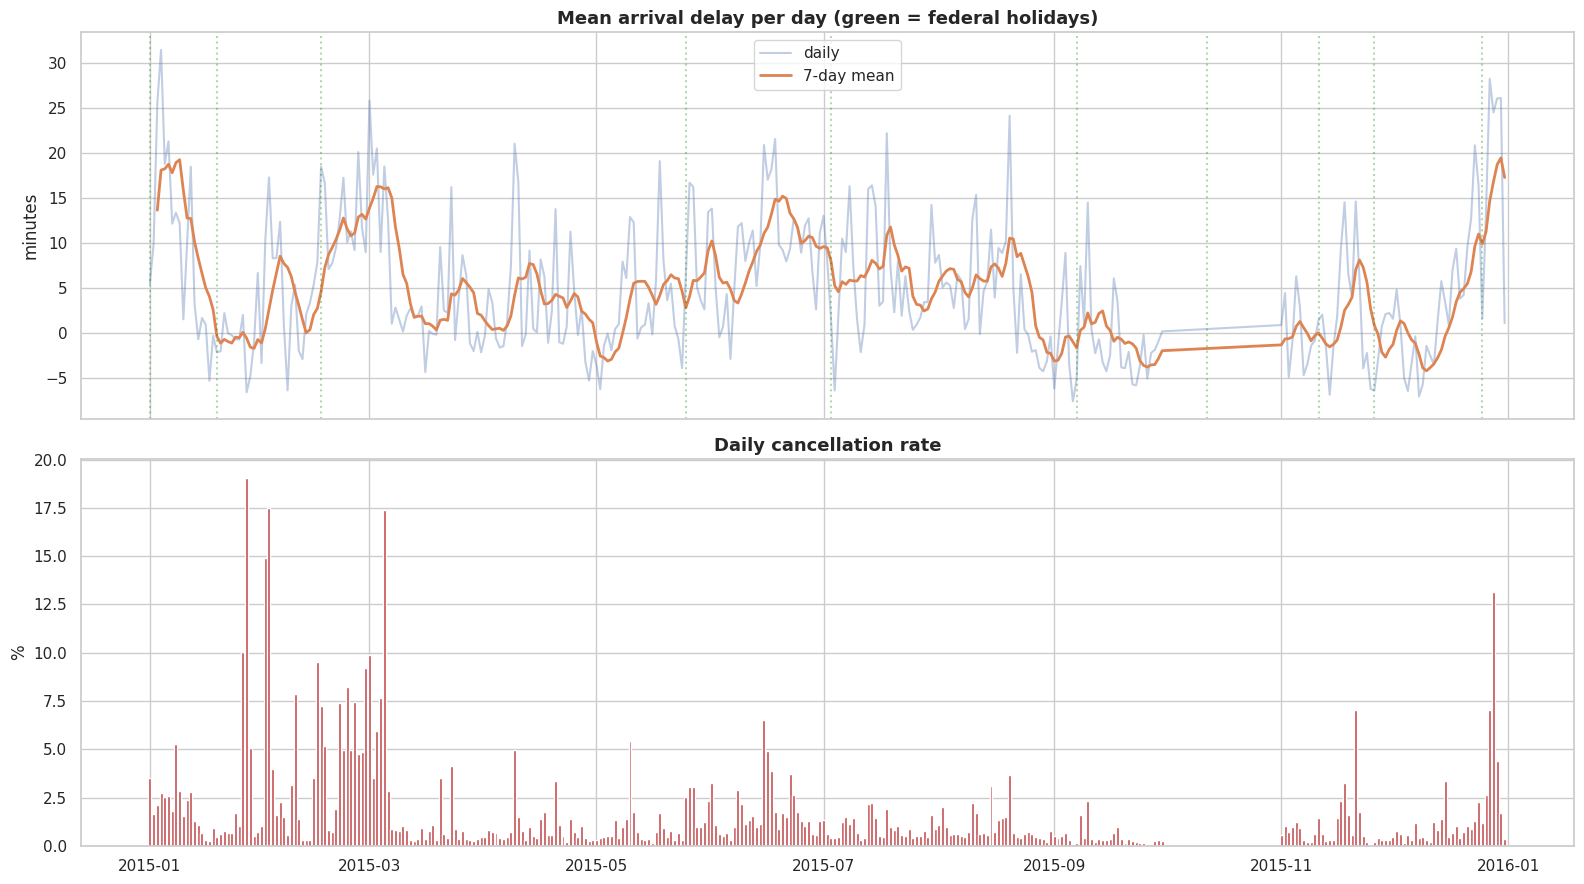

,flights,cancelled,cancel_rate,mean_arr_delay
FLIGHT_DATE,,,,
2015-01-27,11384,2170,0.191,-6.608
2015-02-02,12028,2106,0.175,17.258
2015-03-05,12395,2156,0.174,18.460
2015-02-01,9977,1487,0.149,10.145
2015-12-28,12209,1603,0.131,24.462


In [33]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
axes[0].plot(daily.index, daily["mean_arr_delay"], alpha=.35, label="daily")
axes[0].plot(daily.index, daily["ma_7"], label="7-day mean", lw=2)
for h in holidays[(holidays >= np.datetime64("2015-01-01")) & (holidays <= np.datetime64("2015-12-31"))]:
    axes[0].axvline(h, color="green", alpha=.3, ls=":")
axes[0].set(title="Mean arrival delay per day (green = federal holidays)", ylabel="minutes"); axes[0].legend()
axes[1].bar(daily.index, daily["cancel_rate"] * 100, color="#C44E52")
axes[1].set(title="Daily cancellation rate", ylabel="%")
plt.tight_layout(); savefig("daily_trend"); plt.show()

daily.nlargest(5, "cancel_rate")[["flights", "cancelled", "cancel_rate", "mean_arr_delay"]]

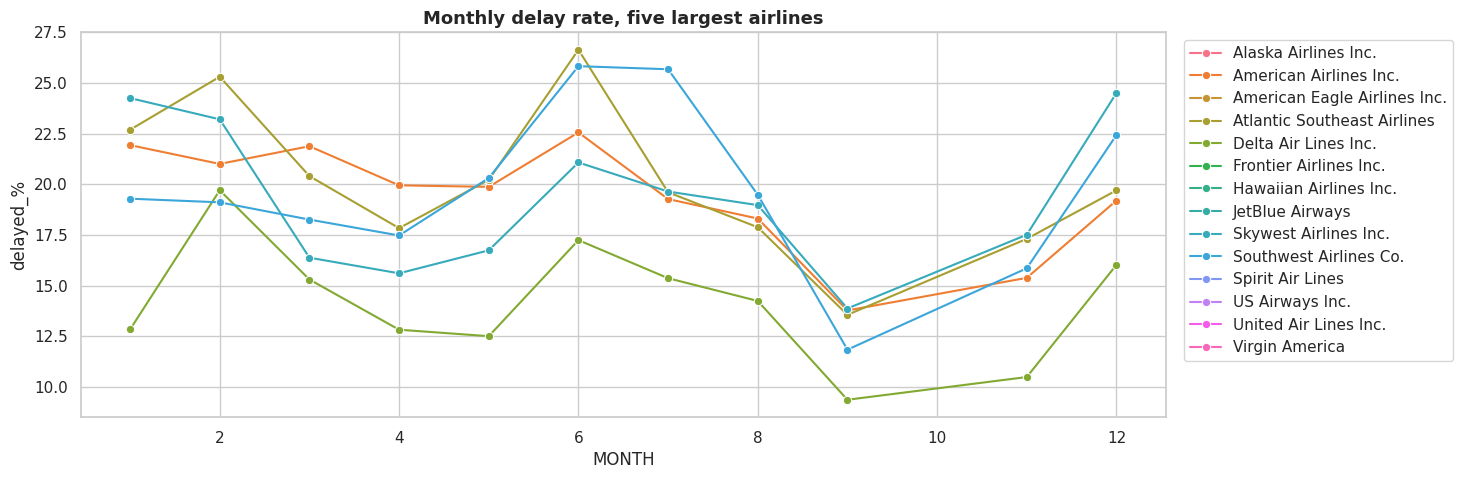

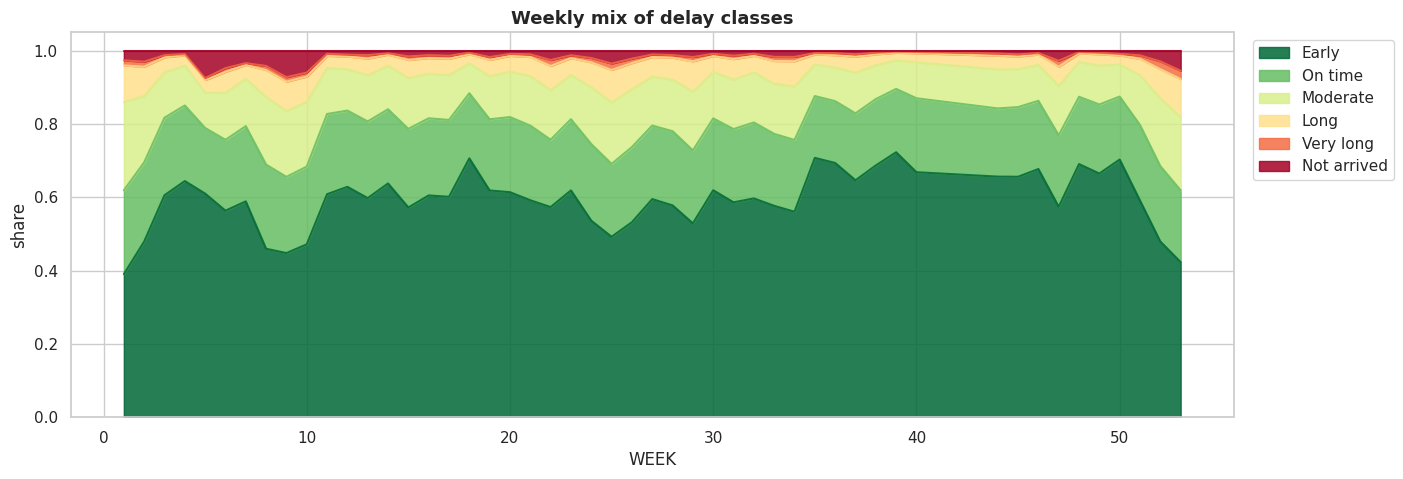

In [34]:
monthly_air = (df[df["AIRLINE_NAME"].isin(top5)].groupby(["MONTH", "AIRLINE_NAME"], observed=True)["DELAYED_15"]
                 .mean().mul(100).rename("delayed_%").reset_index())
plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly_air, x="MONTH", y="delayed_%", hue="AIRLINE_NAME", marker="o")
plt.title("Monthly delay rate, five largest airlines"); plt.legend(bbox_to_anchor=(1.01, 1)); plt.show()

mix = pd.crosstab(df["WEEK"], df["DELAY_CLASS"], normalize="index")
mix.plot.area(figsize=(15, 5), cmap="RdYlGn_r", alpha=.85)
plt.title("Weekly mix of delay classes"); plt.ylabel("share"); plt.legend(bbox_to_anchor=(1.01, 1)); plt.show()

## 12. Bivariate & multivariate analysis

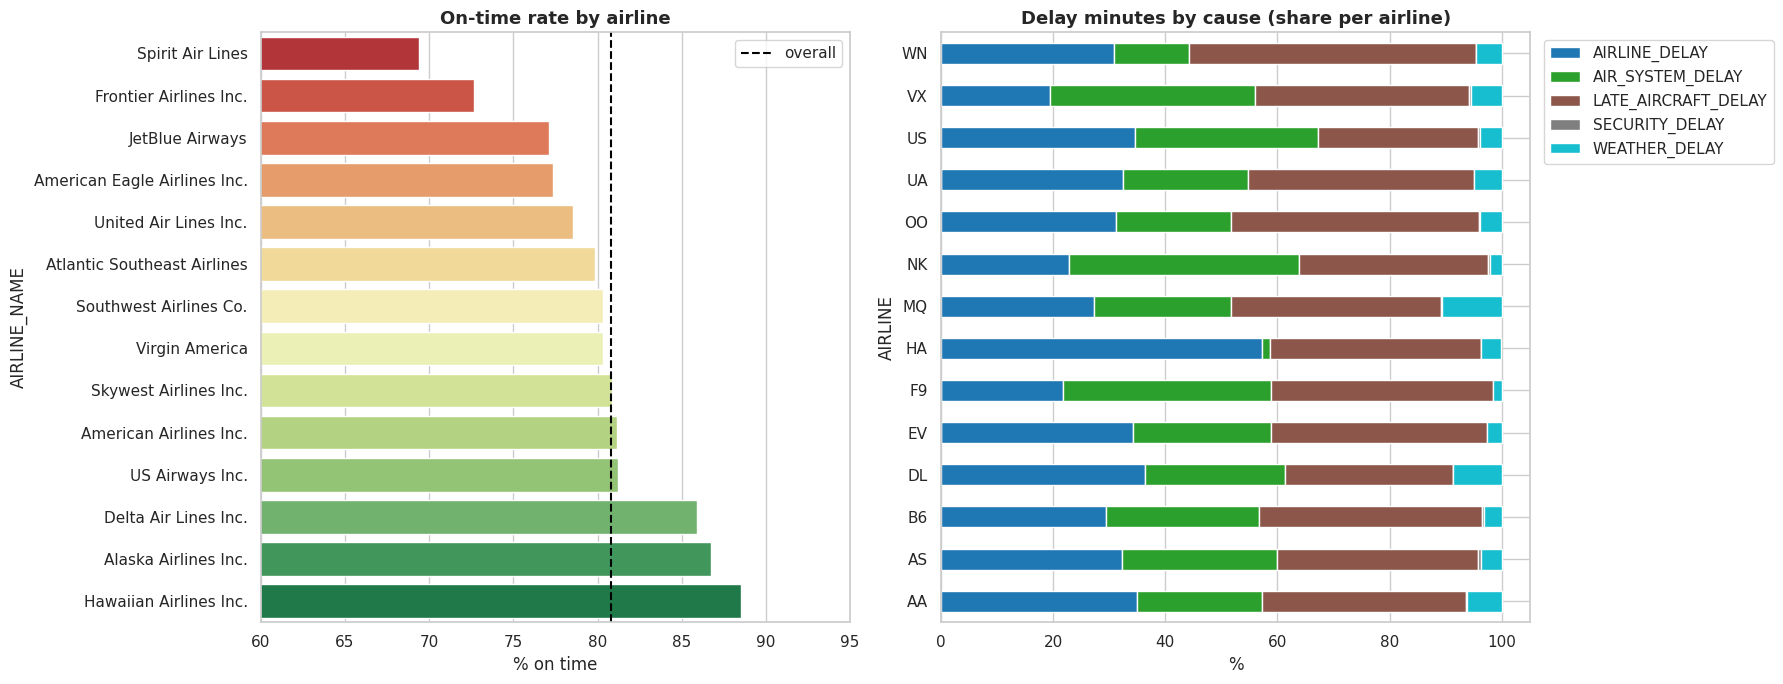

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ot = airline_stats["on_time_rate"].sort_values()
sns.barplot(x=ot.values * 100, y=ot.index.astype(str), ax=axes[0], palette="RdYlGn")
axes[0].axvline((1 - df["DELAYED_15"].mean()) * 100, ls="--", c="black", label="overall")
axes[0].set(title="On-time rate by airline", xlabel="% on time", xlim=(60, 95)); axes[0].legend()

cause_share.plot.barh(stacked=True, ax=axes[1], cmap="tab10")
axes[1].set(title="Delay minutes by cause (share per airline)", xlabel="%"); axes[1].legend(bbox_to_anchor=(1.01, 1))
plt.tight_layout(); savefig("airline_performance"); plt.show()

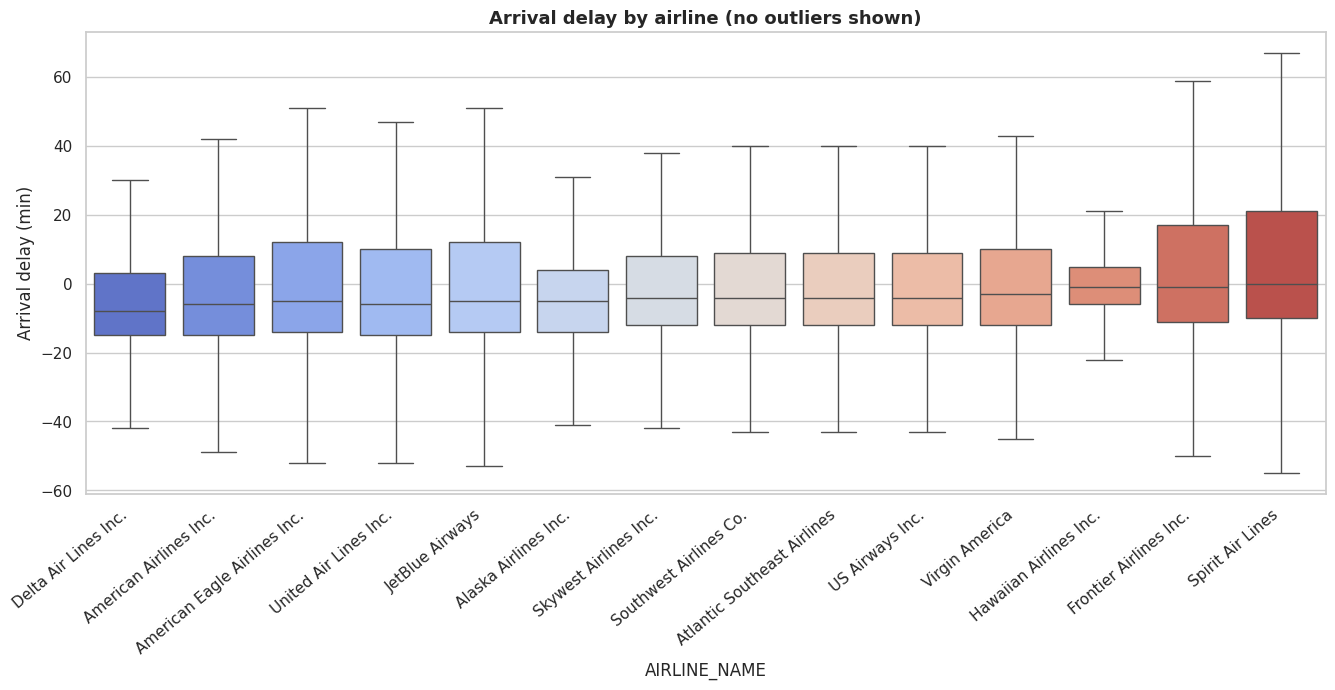

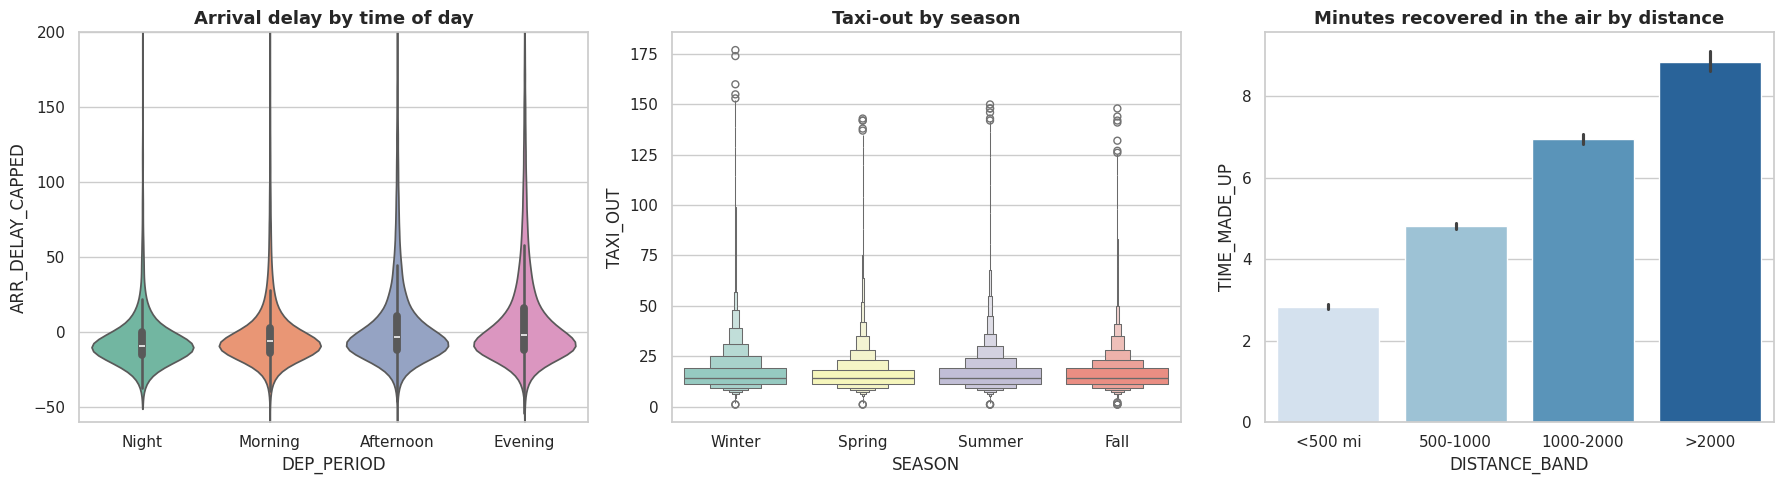

In [36]:
order = airline_stats.sort_values("median_arr_delay").index.astype(str)
plt.figure(figsize=(16, 6))
sns.boxplot(data=sample.assign(AIRLINE_NAME=lambda d: d["AIRLINE_NAME"].astype(str)),
            x="AIRLINE_NAME", y="ARR_DELAY_CAPPED", order=order, showfliers=False, palette="coolwarm")
plt.xticks(rotation=40, ha="right"); plt.ylabel("Arrival delay (min)"); plt.title("Arrival delay by airline (no outliers shown)"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.violinplot(data=sample, x="DEP_PERIOD", y="ARR_DELAY_CAPPED", ax=axes[0], cut=0, palette="Set2")
sns.boxenplot(data=sample, x="SEASON", y="TAXI_OUT", ax=axes[1], palette="Set3")
sns.barplot(data=sample, x="DISTANCE_BAND", y="TIME_MADE_UP", ax=axes[2], palette="Blues")
axes[0].set_title("Arrival delay by time of day"); axes[1].set_title("Taxi-out by season")
axes[2].set_title("Minutes recovered in the air by distance"); axes[0].set_ylim(-60, 200)
plt.tight_layout(); plt.show()

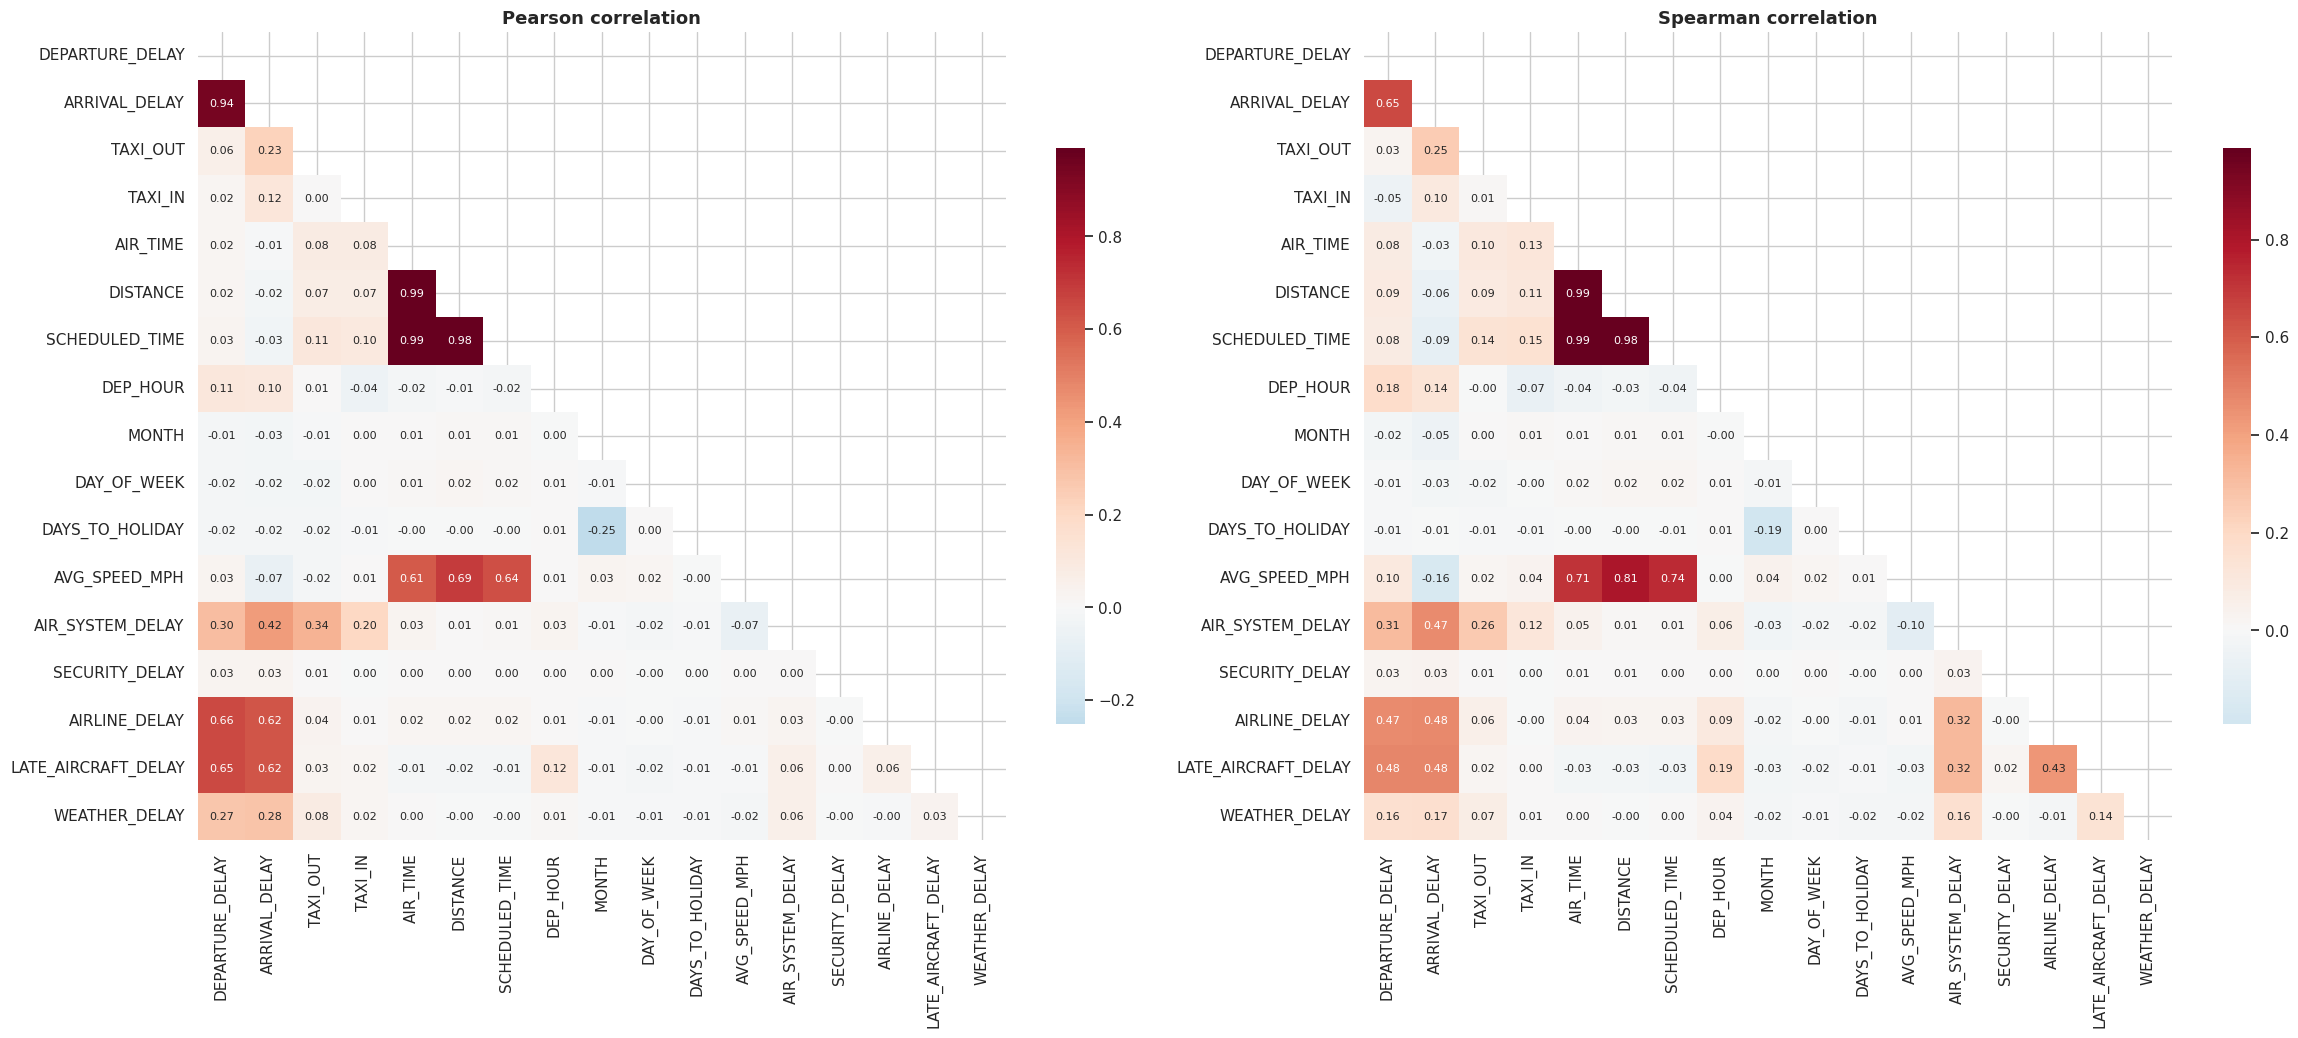

In [37]:
NUM_FEATS = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "AIR_TIME", "DISTANCE", "SCHEDULED_TIME",
             "DEP_HOUR", "MONTH", "DAY_OF_WEEK", "DAYS_TO_HOLIDAY", "AVG_SPEED_MPH"] + CAUSES
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = sample[NUM_FEATS].corr(method=method)
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                ax=ax, square=True, cbar_kws={"shrink": .7}, annot_kws={"size": 8})
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout(); savefig("correlations"); plt.show()

In [ ]:
pp = samp(sample[["DEP_DELAY_CAPPED", "ARR_DELAY_CAPPED", "TAXI_OUT", "AIR_TIME", "DISTANCE", "DEP_PERIOD"]].dropna(), 4_000)
g = sns.pairplot(pp, hue="DEP_PERIOD", corner=True, plot_kws={"alpha": .4, "s": 10}, diag_kind="kde")
g.fig.suptitle("Pair plot (4k flights)", y=1.02); plt.show()

sns.jointplot(data=samp(sample, 50_000), x="DEP_DELAY_CAPPED", y="ARR_DELAY_CAPPED", kind="hex",
              height=7, cmap="mako_r", xlim=(-30, 200), ylim=(-60, 200))
plt.show()

sns.lmplot(data=samp(sample, 20_000), x="DISTANCE", y="AIR_TIME", hue="SEASON",
           scatter_kws={"s": 4, "alpha": .3}, height=5, aspect=1.6)
plt.show()

In [ ]:
sns.catplot(data=sample, x="DEP_PERIOD", y="DELAYED_15", hue="IS_WEEKEND", col="SEASON", kind="point",
            col_wrap=2, height=3.5, aspect=1.4, errorbar=("ci", 95))
plt.show()

hol = df.groupby(df["DAYS_TO_HOLIDAY"].clip(upper=15))["DELAYED_15"].mean().mul(100)
plt.figure(figsize=(10, 4)); hol.plot(marker="o")
plt.title("% delayed vs days from nearest federal holiday"); plt.xlabel("days (15 = 15+)"); plt.ylabel("% delayed"); plt.show()

## 13. Geospatial analysis

In [ ]:
ap_map = origin_stats.dropna(subset=["LATITUDE", "LONGITUDE"])
plt.figure(figsize=(18, 9))
sc = plt.scatter(ap_map["LONGITUDE"], ap_map["LATITUDE"], s=ap_map["departures"] / ap_map["departures"].max() * 1500,
                 c=ap_map["dep_delay"], cmap="RdYlGn_r", alpha=.7, edgecolor="k", linewidth=.3)
for _, r in ap_map.head(15).iterrows():
    plt.annotate(r["ORIGIN_AIRPORT"], (r["LONGITUDE"], r["LATITUDE"]), fontsize=9, ha="center", va="bottom")
plt.colorbar(sc, label="mean departure delay (min)")
plt.xlim(-125, -66); plt.ylim(24, 50)
plt.title("Airports: size = departures, colour = mean departure delay (lower 48)"); savefig("airport_map"); plt.show()

In [ ]:
fig = px.scatter_geo(ap_map.assign(ORIGIN_AIRPORT=lambda d: d["ORIGIN_AIRPORT"].astype(str)),
                     lat="LATITUDE", lon="LONGITUDE", size="departures", color="dep_delay",
                     hover_name="AIRPORT", hover_data={"ORIGIN_AIRPORT": True, "cancel_rate": ":.2%", "destinations": True},
                     color_continuous_scale="RdYlGn_r", scope="usa", size_max=40, title="Airports (hover for details)")
fig.show()

routes = (df.groupby(["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"], observed=True).size().rename("flights").reset_index()
            .nlargest(80, "flights")
            .merge(ap[["IATA_CODE", "LATITUDE", "LONGITUDE"]], left_on="ORIGIN_AIRPORT", right_on="IATA_CODE")
            .merge(ap[["IATA_CODE", "LATITUDE", "LONGITUDE"]], left_on="DESTINATION_AIRPORT", right_on="IATA_CODE",
                   suffixes=("_o", "_d")))
fig = go.Figure()
for _, r in routes.iterrows():
    fig.add_trace(go.Scattergeo(lon=[r["LONGITUDE_o"], r["LONGITUDE_d"]], lat=[r["LATITUDE_o"], r["LATITUDE_d"]],
                                mode="lines", line=dict(width=r["flights"] / routes["flights"].max() * 4, color="royalblue"),
                                opacity=.6, hoverinfo="text", text=f"{r['ORIGIN_AIRPORT']}→{r['DESTINATION_AIRPORT']}: {r['flights']:,}"))
fig.update_layout(title="80 busiest routes", geo=dict(scope="usa"), showlegend=False)
fig.show()

In [ ]:
state_delay = (df.groupby("ORIG_STATE", observed=True)
                 .agg(flights=("FLIGHT_NUMBER", "size"), delayed_rate=("DELAYED_15", "mean"),
                      cancel_rate=("CANCELLED", "mean")).reset_index())
state_delay["ORIG_STATE"] = state_delay["ORIG_STATE"].astype(str)
px.choropleth(state_delay, locations="ORIG_STATE", locationmode="USA-states", scope="usa", color="delayed_rate",
              hover_data={"flights": ":,", "cancel_rate": ":.2%"}, color_continuous_scale="Reds",
              title="Share of delayed departures by origin state").show()

## 14. Route network analysis

In [ ]:
out_deg = df.groupby("ORIGIN_AIRPORT", observed=True)["DESTINATION_AIRPORT"].nunique().rename("out_degree")
in_deg = df.groupby("DESTINATION_AIRPORT", observed=True)["ORIGIN_AIRPORT"].nunique().rename("in_degree")
volume = df["ORIGIN_AIRPORT"].value_counts().rename("departures")
hubs = pd.concat([out_deg, in_deg, volume], axis=1).fillna(0)
hubs["degree"] = hubs["out_degree"] + hubs["in_degree"]
hubs = hubs.join(ap.set_index("IATA_CODE")[["AIRPORT", "CITY", "STATE"]]).sort_values("degree", ascending=False)
display(hubs.head(15))

hub_share = (df.groupby(["AIRLINE_NAME", "ORIGIN_AIRPORT"], observed=True).size().rename("n").reset_index()
               .sort_values("n", ascending=False).groupby("AIRLINE_NAME", observed=True)
               .agg(main_hub=("ORIGIN_AIRPORT", "first"), hub_flights=("n", "first"), total=("n", "sum")))
hub_share["hub_concentration_%"] = hub_share["hub_flights"] / hub_share["total"] * 100
hub_share.sort_values("hub_concentration_%", ascending=False)

In [ ]:
pair = df.groupby(["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"], observed=True).size().rename("ab").reset_index()
pair = pair.merge(pair.rename(columns={"ORIGIN_AIRPORT": "DESTINATION_AIRPORT", "DESTINATION_AIRPORT": "ORIGIN_AIRPORT", "ab": "ba"}),
                  on=["ORIGIN_AIRPORT", "DESTINATION_AIRPORT"], how="left").fillna({"ba": 0})
pair["imbalance"] = (pair["ab"] - pair["ba"]) / (pair["ab"] + pair["ba"])
print(f"Routes: {len(pair):,} | one-directional routes: {(pair['ba'] == 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(hubs["degree"], bins=50, log_scale=(False, True), ax=axes[0]); axes[0].set_title("Degree distribution (log y)")
sns.scatterplot(data=hubs, x="degree", y="departures", ax=axes[1], alpha=.6)
for name, r in hubs.head(8).iterrows():
    axes[1].annotate(name, (r["degree"], r["departures"]), fontsize=9)
axes[1].set_title("Connections vs traffic"); plt.tight_layout(); plt.show()

## 15. Statistical tests (SciPy)

In [ ]:
s = samp(df.loc[df["STATUS"] == "Completed"], 50_000)
print("Shapiro (arrival delay, 5k):", stats.shapiro(s["ARRIVAL_DELAY"].iloc[:5000]))
print("D'Agostino K² (arrival delay):", stats.normaltest(s["ARRIVAL_DELAY"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(s["ARRIVAL_DELAY"], dist="norm", plot=axes[0]); axes[0].set_title("Q-Q arrival delay")
stats.probplot(np.log(s["TAXI_OUT"]), dist="norm", plot=axes[1]); axes[1].set_title("Q-Q log taxi-out")
plt.tight_layout(); plt.show()

In [ ]:
def cramers_v(x, y):
    tbl = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(tbl)
    return chi2, p, dof, np.sqrt(chi2 / (tbl.to_numpy().sum() * (min(tbl.shape) - 1)))

rows = []
for col in ["AIRLINE", "DEP_PERIOD", "SEASON", "IS_WEEKEND", "DAY_OF_WEEK", "DISTANCE_BAND", "MONTH", "TAXI_OUT_Q"]:
    chi2, p, dof, v = cramers_v(s[col], s["DELAYED_15"])
    rows.append({"variable": col, "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": v})
pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

In [ ]:
for col, mask, label in [("ARRIVAL_DELAY", s["IS_WEEKEND"], "weekend vs weekday"),
                         ("TAXI_OUT", s["DELAYED_15"] == 1, "delayed vs on-time"),
                         ("DEPARTURE_DELAY", s["DEP_PERIOD"] == "Evening", "evening vs rest")]:
    a, b = s.loc[mask, col], s.loc[~mask, col]
    _, t_p = stats.ttest_ind(a, b, equal_var=False)
    _, u_p = stats.mannwhitneyu(a, b)
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"{col:<16} {label:<20} Welch p={t_p:.2e} | Mann-Whitney p={u_p:.2e} | Cohen's d={d:+.3f}")

groups = [g["ARRIVAL_DELAY"].to_numpy() for _, g in s.groupby("AIRLINE", observed=True)]
print("\nOne-way ANOVA arrival delay ~ airline:", stats.f_oneway(*groups))
print("Kruskal-Wallis:", stats.kruskal(*groups))
print("Levene:", stats.levene(*groups))

In [ ]:
r, p = stats.pearsonr(s["DEPARTURE_DELAY"], s["ARRIVAL_DELAY"]); print(f"Pearson dep~arr r={r:.3f}, p={p:.2e}")
rho, p = stats.spearmanr(s["TAXI_OUT"], s["ARRIVAL_DELAY"]); print(f"Spearman taxi_out~arr rho={rho:.3f}, p={p:.2e}")
tau, p = stats.kendalltau(s["DEP_HOUR"].iloc[:10000], s["DEPARTURE_DELAY"].iloc[:10000]); print(f"Kendall hour~dep tau={tau:.3f}")

boot = stats.bootstrap((s["ARRIVAL_DELAY"].to_numpy()[:10_000],), np.median, n_resamples=2000,
                       method="percentile", batch=200, random_state=SEED)
print(f"Median arrival delay 95% CI: [{boot.confidence_interval.low:.1f}, {boot.confidence_interval.high:.1f}] min")

done_all = df["DELAYED_15"].dropna()
k, n = int((done_all == 0).sum()), len(done_all)
ci = stats.binomtest(k, n).proportion_ci(method="wilson")
print(f"On-time rate {k / n:.3%}  95% CI [{ci.low:.3%}, {ci.high:.3%}]")

x = s["TAXI_OUT"].to_numpy(dtype="float64")
for name in ["norm", "lognorm", "gamma"]:
    dist = getattr(stats, name); params = dist.fit(x)
    ks = stats.kstest(x, lambda v, d=dist, p=params: d.cdf(v, *p))
    print(f"Taxi-out fit {name:<8} KS={ks.statistic:.4f}")

## 16. Statistical modelling & time series (statsmodels)

In [ ]:
m = samp(df.loc[df["STATUS"] == "Completed"], 200_000).copy()
m["IS_WEEKEND"] = m["IS_WEEKEND"].astype(int)
m["AIRLINE"] = m["AIRLINE"].astype(str)
ols = smf.ols("ARRIVAL_DELAY ~ DEPARTURE_DELAY + TAXI_OUT + TAXI_IN + DISTANCE + C(AIRLINE) + C(DEP_PERIOD) + C(SEASON) + IS_WEEKEND",
              data=m).fit(cov_type="HC3")
print(ols.summary().tables[0]); print(ols.summary().tables[1])

In [ ]:
logit = smf.logit("DELAYED_15 ~ C(AIRLINE) + C(DEP_PERIOD) + C(SEASON) + DISTANCE + IS_WEEKEND + DAYS_TO_HOLIDAY",
                  data=m).fit(disp=0, maxiter=200)
odds = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]),
                     "ci_high": np.exp(logit.conf_int()[1]), "p_value": logit.pvalues}).drop("Intercept")
print(f"Pseudo R²: {logit.prsquared:.3f}")
odds.sort_values("odds_ratio")

In [ ]:
or_plot = odds.sort_values("odds_ratio")
plt.figure(figsize=(9, 9))
plt.errorbar(or_plot["odds_ratio"], or_plot.index, fmt="o", capsize=3,
             xerr=[or_plot["odds_ratio"] - or_plot["ci_low"], or_plot["ci_high"] - or_plot["odds_ratio"]])
plt.axvline(1, color="red", ls="--"); plt.xscale("log"); plt.title("Odds ratios for a delay ≥ 15 min (95% CI)"); plt.show()

In [ ]:
ts = daily["mean_arr_delay"].asfreq("D").interpolate()
decomp = seasonal_decompose(ts, model="additive", period=7)
fig = decomp.plot(); fig.set_size_inches(14, 9); plt.show()

adf = adfuller(ts.dropna())
print(f"ADF statistic={adf[0]:.3f}, p={adf[1]:.4f} → {'stationary' if adf[1] < .05 else 'non-stationary'}")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(ts, lags=40, ax=axes[0]); plot_pacf(ts, lags=40, ax=axes[1], method="ywm"); plt.show()

In [ ]:
vol = daily["flights"].asfreq("D").interpolate()
train, test = vol.iloc[:-28], vol.iloc[-28:]
sarima = SARIMAX(np.log(train), order=(1, 0, 1), seasonal_order=(1, 1, 1, 7),
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = sarima.get_forecast(steps=len(test))
pred, ci = np.exp(fc.predicted_mean), np.exp(fc.conf_int())
pred.index = ci.index = test.index
mape = np.mean(np.abs((test - pred) / test)) * 100
plt.figure(figsize=(15, 5))
plt.plot(train.index[-90:], train.iloc[-90:], label="train")
plt.plot(test.index, test, label="actual", color="black")
plt.plot(pred.index, pred, label=f"forecast (MAPE {mape:.1f}%)", color="red")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=.15)
plt.title("SARIMA forecast of daily flight volume (last 4 weeks)"); plt.legend(); plt.show()

## 17. Interactive dashboards (Plotly)

In [ ]:
sb = samp(df.loc[df["STATUS"] == "Completed"], 500_000)[["AIRLINE_NAME", "DEP_PERIOD", "DELAY_CLASS"]].astype(str)
px.sunburst(sb, path=["AIRLINE_NAME", "DEP_PERIOD", "DELAY_CLASS"], title="Airline → time of day → delay class").show()

tm = origin_stats.dropna(subset=["STATE"]).astype({"ORIGIN_AIRPORT": str})
px.treemap(tm, path=["STATE", "ORIGIN_AIRPORT"], values="departures", color="dep_delay",
           color_continuous_scale="RdYlGn_r", title="Departures by state and airport (colour = mean delay)").show()

In [ ]:
mon = df.groupby(["MONTH", "AIRLINE_NAME"], observed=True)["DELAYED_15"].mean().mul(100).rename("delayed_%").reset_index()
mon["AIRLINE_NAME"] = mon["AIRLINE_NAME"].astype(str)
px.line(mon, x="MONTH", y="delayed_%", color="AIRLINE_NAME", markers=True, title="Monthly delay rate by airline").show()

px.density_heatmap(samp(df, 500_000), x="DEP_HOUR", y="MONTH", z="ARR_DELAY_CAPPED", histfunc="avg",
                   nbinsx=24, nbinsy=12, color_continuous_scale="RdYlGn_r", title="Mean arrival delay: month × hour").show()

anim = (df.groupby(["MONTH", "ORIG_STATE"], observed=True)["DELAYED_15"].mean().mul(100)
          .rename("delayed_%").reset_index().astype({"ORIG_STATE": str}))
px.choropleth(anim, locations="ORIG_STATE", locationmode="USA-states", scope="usa", color="delayed_%",
              animation_frame="MONTH", range_color=(0, anim["delayed_%"].quantile(.95)), color_continuous_scale="Reds",
              title="Delay rate by state, month by month (press play)").show()

perf = airline_stats.reset_index().astype({"AIRLINE_NAME": str})
px.scatter(perf, x="cancel_rate", y="on_time_rate", size="flights", color="AIRLINE_NAME", text="AIRLINE_NAME",
           title="Airlines: cancellations vs punctuality (bubble = flights)").update_traces(textposition="top center").show()

## 18. Unsupervised learning

In [ ]:
prof_cols = ["departures", "dep_delay", "taxi_out", "cancel_rate", "destinations"]
prof = origin_stats.query("departures >= 1000").dropna(subset=prof_cols + ["LATITUDE", "LONGITUDE"]).copy()
Zp = StandardScaler().fit_transform(np.column_stack([np.log1p(prof["departures"]), prof[prof_cols[1:]]]))
pca = PCA().fit(Zp)
pcs = pca.transform(Zp)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(range(1, len(prof_cols) + 1), pca.explained_variance_ratio_, label="per component")
axes[0].plot(range(1, len(prof_cols) + 1), np.cumsum(pca.explained_variance_ratio_), "o-r", label="cumulative")
axes[0].set(title="PCA explained variance (airport profiles)", xlabel="component"); axes[0].legend()
axes[1].scatter(pcs[:, 0], pcs[:, 1], alpha=.6)
for i, code_ in enumerate(prof["ORIGIN_AIRPORT"].astype(str)):
    if prof["departures"].iloc[i] > prof["departures"].quantile(.9):
        axes[1].annotate(code_, (pcs[i, 0], pcs[i, 1]), fontsize=8)
for j, name in enumerate(prof_cols):
    axes[1].arrow(0, 0, pca.components_[0, j] * 3, pca.components_[1, j] * 3, color="red", head_width=.08)
    axes[1].text(pca.components_[0, j] * 3.3, pca.components_[1, j] * 3.3, name, color="red")
axes[1].set(title="PCA biplot of airports", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

In [ ]:
ks = range(2, min(11, len(prof)))
inertia, sil = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Zp)
    inertia.append(km_k.inertia_); sil.append(silhouette_score(Zp, km_k.labels_))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_title("Elbow")
axes[1].plot(list(ks), sil, "o-", color="green"); axes[1].set_title("Silhouette score")
plt.show()

K = list(ks)[int(np.argmax(sil))]
prof["cluster"] = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit_predict(Zp)
display(prof.groupby("cluster")[prof_cols].mean().round(3).assign(n_airports=prof["cluster"].value_counts().sort_index()))

plt.figure(figsize=(16, 8))
sns.scatterplot(data=prof, x="LONGITUDE", y="LATITUDE", hue="cluster", size="departures", sizes=(20, 600), palette="tab10", alpha=.75)
plt.xlim(-125, -66); plt.ylim(24, 50); plt.title(f"Airport clusters (K = {K}, best silhouette)")
plt.legend(bbox_to_anchor=(1.01, 1)); plt.show()

In [ ]:
coords = np.radians(ap.dropna(subset=["LATITUDE", "LONGITUDE"])[["LATITUDE", "LONGITUDE"]].to_numpy())
db = DBSCAN(eps=200 / 6371.0, min_samples=4, metric="haversine", algorithm="ball_tree").fit(coords)
labels = db.labels_
print(f"DBSCAN: {len(set(labels)) - (1 if -1 in labels else 0)} regional airport groups, {np.mean(labels == -1):.0%} isolated airports")
deg = np.degrees(coords)
plt.figure(figsize=(16, 8))
plt.scatter(deg[labels == -1, 1], deg[labels == -1, 0], s=12, c="lightgrey", label="isolated")
plt.scatter(deg[labels != -1, 1], deg[labels != -1, 0], s=20, c=labels[labels != -1], cmap="tab20")
plt.xlim(-125, -66); plt.ylim(24, 50); plt.title("DBSCAN: airports within 200 km of each other"); plt.legend(); plt.show()

## 19. Predicting delays (scikit-learn)

In [ ]:
NUM_ML = ["MONTH", "DAY", "DAY_OF_WEEK", "DAY_OF_YEAR", "DEP_HOUR", "ARR_HOUR", "SCHEDULED_TIME", "DISTANCE", "DAYS_TO_HOLIDAY"]
CAT_ML = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "DEP_PERIOD"]

ml = samp(df.loc[df["STATUS"] == "Completed"], 600_000)
X = ml[NUM_ML + CAT_ML].copy()
for c in CAT_ML:
    X[c] = X[c].astype(str)
y = ml["DELAYED_15"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print(f"train {X_train.shape}, test {X_test.shape}, delayed rate {y.mean():.2%}")

In [ ]:
results = {}
logreg = Pipeline([
    ("prep", ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_ML),
                                ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), CAT_ML)])),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
ord_prep = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                     encoded_missing_value=-1, max_categories=200), CAT_ML),
                              ("num", "passthrough", NUM_ML)])
hgb = Pipeline([("prep", ord_prep),
                ("clf", HistGradientBoostingClassifier(max_iter=400, learning_rate=.08, max_leaf_nodes=63,
                                                       categorical_features=list(range(len(CAT_ML))),
                                                       class_weight="balanced", early_stopping=True, random_state=SEED))])
rf = Pipeline([("prep", ord_prep),
               ("clf", RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=20,
                                              class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])

for name, model in [("Logistic regression", logreg), ("Random forest", rf), ("Hist gradient boosting", hgb)]:
    t = time.time()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {"ROC_AUC": roc_auc_score(y_test, proba), "PR_AUC": average_precision_score(y_test, proba),
                     "F1": f1_score(y_test, proba >= .5), "fit_s": time.time() - t, "model": model}
    print(f"{name:<24} ROC-AUC {results[name]['ROC_AUC']:.3f} | PR-AUC {results[name]['PR_AUC']:.3f} | {results[name]['fit_s']:.0f}s")
pd.DataFrame(results).T.drop(columns="model")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for name, r in results.items():
    RocCurveDisplay.from_estimator(r["model"], X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(r["model"], X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_title("ROC curves"); axes[1].set_title("Precision-recall curves")
best_name = max(results, key=lambda k: results[k]["ROC_AUC"]); best = results[best_name]["model"]
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, normalize="true", cmap="Blues", ax=axes[2],
                                      display_labels=["On time", "Delayed"])
axes[2].set_title(f"Confusion matrix: {best_name}"); axes[2].grid(False)
plt.tight_layout(); savefig("model_eval"); plt.show()
print(classification_report(y_test, best.predict(X_test), target_names=["On time", "Delayed"]))

In [ ]:
proba = best.predict_proba(X_test)[:, 1]
thr = np.linspace(.05, .95, 91)
f1s = [f1_score(y_test, proba >= t) for t in thr]
best_t = thr[int(np.argmax(f1s))]
plt.figure(figsize=(9, 4)); plt.plot(thr, f1s); plt.axvline(best_t, ls="--", c="red")
plt.title(f"F1 vs threshold (best {best_t:.2f} → F1 {max(f1s):.3f})"); plt.xlabel("threshold"); plt.show()

idx = rng.choice(len(X_test), size=min(20_000, len(X_test)), replace=False)
pi = permutation_importance(best, X_test.iloc[idx], y_test.iloc[idx], n_repeats=3, scoring="roc_auc", random_state=SEED, n_jobs=-1)
pd.Series(pi.importances_mean, index=X_test.columns).sort_values().plot.barh(figsize=(9, 6), color="#4C72B0")
plt.title(f"Permutation importance ({best_name})"); plt.show()

cv = cross_val_score(hgb, X_train.iloc[:150_000], y_train.iloc[:150_000],
                     cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"CV ROC-AUC: {cv.mean():.3f} ± {cv.std():.3f}")

In [ ]:
NUM_LIVE = NUM_ML + ["DEPARTURE_DELAY", "TAXI_OUT"]
Xl = ml[NUM_LIVE + CAT_ML].copy()
for c in CAT_ML:
    Xl[c] = Xl[c].astype(str)
Xl_train, Xl_test = Xl.loc[X_train.index], Xl.loc[X_test.index]
live_prep = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                      encoded_missing_value=-1, max_categories=200), CAT_ML),
                               ("num", "passthrough", NUM_LIVE)])
live_clf = Pipeline([("prep", live_prep), ("clf", HistGradientBoostingClassifier(max_iter=300, categorical_features=list(range(len(CAT_ML))),
                                                                                random_state=SEED))]).fit(Xl_train, y_train)
print(f"After pushback (with departure delay + taxi-out): ROC-AUC {roc_auc_score(y_test, live_clf.predict_proba(Xl_test)[:, 1]):.3f}"
      f" vs at booking {results[best_name]['ROC_AUC']:.3f}")

y_reg = ml["ARRIVAL_DELAY"]
reg = Pipeline([("prep", live_prep), ("reg", HistGradientBoostingRegressor(max_iter=300, loss="absolute_error",
                                                                          categorical_features=list(range(len(CAT_ML))),
                                                                          random_state=SEED))])
reg.fit(Xl_train, y_reg.loc[X_train.index])
pred_reg = reg.predict(Xl_test)
true_reg = y_reg.loc[X_test.index]
print(f"Arrival-delay regression: MAE {mean_absolute_error(true_reg, pred_reg):.2f} min | R² {r2_score(true_reg, pred_reg):.3f}"
      f" | baseline MAE {mean_absolute_error(true_reg, np.full(len(true_reg), y_reg.loc[X_train.index].median())):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
k = rng.choice(len(true_reg), size=min(20_000, len(true_reg)), replace=False)
axes[0].scatter(true_reg.iloc[k], pred_reg[k], s=3, alpha=.3)
axes[0].plot([-60, 400], [-60, 400], "r--"); axes[0].set(xlim=(-60, 400), ylim=(-60, 400), xlabel="actual", ylabel="predicted",
                                                        title="Predicted vs actual arrival delay")
sns.histplot(true_reg - pred_reg, bins=100, ax=axes[1]); axes[1].set(xlim=(-100, 100), title="Residuals")
plt.tight_layout(); plt.show()

## 20. Export & key findings

In [ ]:
os.makedirs("outputs", exist_ok=True)
try:
    df.to_parquet("outputs/flights_clean.parquet", index=False)
    print("Saved outputs/flights_clean.parquet")
except ImportError:
    samp(df, 500_000).to_csv("outputs/flights_clean_sample.csv.gz", index=False)
    print("pyarrow not installed: saved a 500k-row CSV sample")
airline_stats.to_csv("outputs/airline_summary.csv")
origin_stats.to_csv("outputs/airport_summary.csv", index=False)
daily.to_csv("outputs/daily_summary.csv")
pd.DataFrame(results).T.drop(columns="model").to_csv("outputs/model_scores.csv")
print("Figures:", sorted(os.listdir(FIG_DIR)))

In [ ]:
worst_hour = df.groupby("DEP_HOUR")["DELAYED_15"].mean().idxmax()
best_hour = df.groupby("DEP_HOUR")["DELAYED_15"].mean().idxmin()
worst_month = df.groupby("MONTH")["DELAYED_15"].mean().idxmax()
top_cause = df.loc[df["MAIN_CAUSE"] != "None", "MAIN_CAUSE"].value_counts().idxmax()
print("═" * 72)
print(" KEY FINDINGS")
print("═" * 72)
print(f"• Flights analysed: {len(df):,} on {df['ROUTE'].nunique():,} routes between {df['ORIGIN_AIRPORT'].nunique():,} airports")
print(f"• On-time rate (arrival < 15 min late): {1 - df['DELAYED_15'].mean():.1%} | cancelled: {df['CANCELLED'].mean():.2%}")
print(f"• Most punctual airline: {airline_stats['on_time_rate'].idxmax()} | least: {airline_stats['on_time_rate'].idxmin()}")
print(f"• Safest departure hour: {best_hour}:00 | worst: {worst_hour}:00 | worst month: {worst_month}")
print(f"• Most common main delay cause: {top_cause}")
print(f"• Busiest airport: {origin_stats.iloc[0]['AIRPORT']} ({origin_stats.iloc[0]['departures']:,} departures)")
print(f"• Best booking-time model: {best_name}, ROC-AUC {results[best_name]['ROC_AUC']:.3f}")
print("═" * 72)